# Laboratorio 4 — Asistente de compras por voz

**Deep Learning · Maestría en Ciencia de Datos e Inteligencia Artificial — UTEC**

Asistente que recibe consultas **habladas en español**, recupera productos con
**RAG** sobre el *Amazon Shopping Queries Dataset* (ESCI, locale `es`), ejecuta
operaciones sobre una **tienda simulada** mediante un **agente con herramientas**,
y responde **por voz clonada** con XTTS-v2.

---

### Arquitectura

```
  micrófono
     │
     ▼
 ┌─────────┐   texto    ┌──────────────────────────────────────────┐
 │  ASR    │──────────▶ │  CONTROLES EN CÓDIGO (no el LLM)         │
 │ Whisper │            │  · confirmación explícita                │
 └─────────┘            │  · transcripción dudosa → reconfirmar    │
                        └───────────────────┬──────────────────────┘
                                            ▼
                        ┌──────────────────────────────────────────┐
                        │  AGENTE  (bucle decidir → actuar)        │
                        │   LLM Qwen2.5 · JSON de herramientas     │
                        └───┬──────────────────────┬───────────────┘
                            ▼                      ▼
        ┌───────────────────────────┐   ┌────────────────────────────┐
        │  RAG híbrido              │   │  TIENDA SIMULADA           │
        │  BM25 propio + E5 → RRF   │   │  precios · stock · carrito │
        │  → cross-encoder BGE      │   │  cotización · pedido       │
        └───────────────────────────┘   │  atómico · idempotente     │
                            │           └────────────────────────────┘
                            ▼
                ┌───────────────────────────┐
                │ VERIFICACIÓN de la respuesta│  ← toda cifra debe venir
                └───────────┬───────────────┘     de una herramienta
                            ▼
                      ┌──────────┐
                      │   TTS    │  XTTS-v2, voz clonada de una
                      │ clonada  │  grabación de referencia
                      └──────────┘
```

### Contenido

| § | Sección |
|---|---|
| 1 | Entorno y dependencias |
| 2 | Código del proyecto |
| 3 | Datos ESCI: catálogo, consultas y juicios |
| 4 | Tienda simulada reproducible |
| 5 | Índices de recuperación |
| 6 | **Evaluación IR: modelo base léxico y ablaciones** |
| 7 | Voz: referencia, ASR y TTS con clonación |
| 8 | Agente: demostración por texto |
| 9 | Agente: demostración por voz |
| 10 | **24 escenarios operativos** (20 del enunciado + 4 de control) |
| 11 | **6 escenarios por voz + réplica con transcripción correcta** |
| 12 | Métricas de voz y latencia |
| 13 | Informe, figuras y análisis |
| 14 | Gestión de memoria |

> **Tiempo estimado en Colab T4:** ~25 min la primera ejecución completa
> (≈10 min de descarga de ESCI, ≈6 min de índices, ≈5 min de modelos).

---
## 1. Entorno y dependencias

Ejecute esta sección **una sola vez** por sesión de Colab. Si Colab pide
reiniciar el entorno, reinícielo y **vuelva a ejecutar desde la §1** (las celdas
son idempotentes).

> **Requisito del laboratorio:** todo el cómputo ocurre dentro de Colab. No se
> usa ninguna API externa de inferencia; solo se descargan pesos y datos.

In [1]:
#@title 1.1 · Comprobar GPU y RAM
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv || echo "Sin GPU"
import platform, psutil, torch
print(f"\nPython : {platform.python_version()}")
print(f"RAM    : {psutil.virtual_memory().total/1024**3:.1f} GB")
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU    : {p.name} ({p.total_memory/1024**3:.1f} GB)  ->  TODO OK, siga a la 1.2")
else:
    print("GPU    : NO HAY -> Entorno de ejecución -> Cambiar tipo -> T4 GPU")

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07

Python : 3.13.16
RAM    : 12.7 GB
GPU    : Tesla T4 (14.6 GB)  ->  TODO OK, siga a la 1.2


In [2]:
#@title 1.2 · Instalar dependencias (≈4 min)
import os, subprocess, sys

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    # git-lfs es imprescindible: los parquet de ESCI se guardan con LFS.
    subprocess.run("apt-get -qq update && apt-get -qq install -y git-lfs ffmpeg",
                   shell=True, check=False)
    subprocess.run("git lfs install", shell=True, check=False)

PAQUETES = [
    # Núcleo numérico y de datos
    "pandas>=2.0", "pyarrow>=14.0", "scipy>=1.11", "matplotlib>=3.7",
    # Modelos.
    # transformers>=4.57 NO es opcional: coqui-tts lo exige desde su 0.28.0.
    # Las guías de 2025 recomendaban fijar un techo (<4.50) porque XTTS usaba
    # BeamSearchScorer; hacerlo hoy deja el entorno sin resolver.
    "transformers>=4.57", "accelerate>=0.30", "sentencepiece",
    "bitsandbytes>=0.43",
    # Voz
    "faster-whisper>=1.0", "soundfile", "librosa>=0.10",
    # Evaluación
    "jiwer>=3.0",
]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PAQUETES], check=False)

# XTTS-v2: fork mantenido (idiap), en PyPI como coqui-tts; conserva el import
# `from TTS.api import TTS`. Va en su propia llamada para que un fallo suyo no
# arrastre al resto: el código degrada a MMS-TTS y lo deja registrado.
# Desde 0.27.4 no arrastra PyTorch, así que no puede degradar el de Colab.
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "coqui-tts>=0.28"],
               check=False)
# speechbrain da la semejanza de locutor (ECAPA). Si falla, hay respaldo MFCC.
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "speechbrain"],
               check=False)

print("Instalación terminada.")

Instalación terminada.


In [3]:
#@title 1.3 · Comprobación previa (30 s) — hágala ANTES de gastar la sesión
#@markdown Verifica las cuatro cosas que de verdad fallan en Colab: git-lfs,
#@markdown ffmpeg, la compatibilidad transformers ↔ coqui-tts, y que XTTS
#@markdown importe. Si algo sale PROBLEMA, arréglelo antes de seguir.
import os, shutil, subprocess, sys
os.environ["COQUI_TOS_AGREED"] = "1"   # licencia CPML (uso no comercial)

fallos = []

def _v(mod):
    try:
        return getattr(__import__(mod), "__version__", "?")
    except Exception as e:
        return f"NO DISPONIBLE ({type(e).__name__})"

print("VERSIONES")
for m in ("torch", "transformers", "pandas", "scipy", "faster_whisper"):
    print(f"  {m:16s} {_v(m)}")

# 1) Binarios del sistema.
print("\nBINARIOS")
for exe, para_que in (("git-lfs", "descargar los parquet de ESCI"),
                      ("ffmpeg", "convertir el audio del micrófono")):
    ruta = shutil.which(exe)
    print(f"  {exe:10s} {'OK ' + str(ruta) if ruta else 'FALTA'}  ({para_que})")
    if not ruta:
        fallos.append(f"falta {exe}: !apt-get install -y {exe}")

# 2) transformers debe satisfacer lo que exige coqui-tts (>=4.57 desde 0.28.0).
print("\nCOMPATIBILIDAD")
try:
    import transformers
    from packaging.version import Version
    tv = Version(transformers.__version__)
    ok = tv >= Version("4.57")
    print(f"  transformers {tv} {'>=' if ok else '<'} 4.57 requerido por coqui-tts"
          f"  ->  {'OK' if ok else 'PROBLEMA'}")
    if not ok:
        fallos.append("transformers por debajo de 4.57: reejecute la celda 1.2")
except Exception as e:
    fallos.append(f"no se pudo comprobar transformers: {e}")

# 3) XTTS debe importar. Si no, habrá voz, pero SIN clonación.
try:
    from TTS.api import TTS as _T
    print(f"  coqui-tts {_v('TTS')} importa  ->  OK (habrá clonación de voz)")
except Exception as e:
    print(f"  coqui-tts NO importa: {type(e).__name__}: {str(e)[:90]}")
    fallos.append("XTTS no disponible: habrá voz SIN clonación (el enunciado "
                  "exige clonada). Reejecute 1.2 y, si persiste, reinicie el "
                  "entorno y vuelva a ejecutar desde la §1.")

# 4) GPU.
import torch
print("\nGPU")
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"  {p.name} ({p.total_memory/1024**3:.1f} GB)")
else:
    print("  SIN GPU")
    fallos.append("sin GPU: Entorno de ejecución -> Cambiar tipo -> T4 GPU")

print("\n" + "="*68)
if fallos:
    print("REVISE ESTO ANTES DE SEGUIR:")
    for f in fallos:
        print(f"  - {f}")
else:
    print("Todo en orden. Puede continuar con la §2.")

VERSIONES
  torch            2.14.1+cu130
  transformers     5.22.1
  pandas           2.2.3
  scipy            1.16.3
  faster_whisper   1.2.1

BINARIOS
  git-lfs    OK /usr/bin/git-lfs  (descargar los parquet de ESCI)
  ffmpeg     OK /usr/bin/ffmpeg  (convertir el audio del micrófono)

COMPATIBILIDAD
  transformers 5.22.1 >= 4.57 requerido por coqui-tts  ->  OK
  coqui-tts 0.28.0 importa  ->  OK (habrá clonación de voz)

GPU
  Tesla T4 (14.6 GB)

Todo en orden. Puede continuar con la §2.


---
## 2. Código del proyecto

Elija **una** de las tres formas de poner `src/voiceshop` al alcance del
notebook. La opción A (subir el ZIP) es la más simple para la entrega.

In [4]:
#@title 2.1 · Cargar el código del proyecto
import os, shutil, sys, zipfile
from pathlib import Path


def extraer_zip(zip_path, destino="/content"):
    # Extrae normalizando la barra invertida a '/' en los nombres de entrada.
    #
    # Compress-Archive de PowerShell escribe los separadores con barra
    # invertida, violando la especificación ZIP. En Windows pasa inadvertido,
    # pero en Linux la barra invertida no separa directorios: extractall
    # crearía ficheros planos llamados "Laboratorio4\src\agent.py" y no
    # habría ningún paquete importable. Reescribir el nombre al extraer lo
    # evita, venga el ZIP de donde venga.
    destino = Path(destino)
    with zipfile.ZipFile(zip_path) as z:
        for info in z.infolist():
            nombre = info.filename.replace("\\", "/")
            if not nombre or nombre.startswith(("/", "../")) or "/../" in nombre:
                continue                      # nunca escribir fuera de destino
            ruta = destino / nombre
            if nombre.endswith("/"):
                ruta.mkdir(parents=True, exist_ok=True)
                continue
            ruta.parent.mkdir(parents=True, exist_ok=True)
            with z.open(info) as src, open(ruta, "wb") as dst:
                shutil.copyfileobj(src, dst)


def limpiar_restos(destino="/content"):
    # Borra los ficheros planos que haya dejado una extracción anterior.
    n = 0
    for p in list(Path(destino).iterdir()):
        if "\\" in p.name:
            p.unlink()
            n += 1
    if n:
        print(f"  limpiados {n} ficheros de una extracción previa incorrecta")

EN_COLAB = "google.colab" in sys.modules
ORIGEN = "zip"   #@param ["zip", "drive", "git", "local"]
REPO_GIT = ""    #@param {type:"string"}
RUTA_DRIVE = "/content/drive/MyDrive/Laboratorio4"   #@param {type:"string"}

if not EN_COLAB:
    PROJECT_DIR = Path.cwd()
    if not (PROJECT_DIR / "src").exists() and (PROJECT_DIR.parent / "src").exists():
        PROJECT_DIR = PROJECT_DIR.parent
elif ORIGEN == "zip":
    from google.colab import files
    # No se presupone dónde cae la extracción: se busca `voiceshop` a
    # cualquier profundidad. Un ZIP puede traer carpeta raíz, no traerla, o
    # traer una con otro nombre, y cada combinación deja el código en un sitio
    # distinto. Buscarlo es más corto que enumerar los casos.
    def _localizar():
        hits = sorted(Path("/content").rglob("voiceshop/__init__.py"))
        return hits[0].parents[2] if hits else None

    PROJECT_DIR = _localizar()
    if PROJECT_DIR is None:
        limpiar_restos()
        zips = sorted(Path("/content").glob("*.zip"))
        if not zips:
            print("Suba el ZIP del proyecto (debe contener src/, scripts/, tests/)...")
            files.upload()
            zips = sorted(Path("/content").glob("*.zip"))
        for z_path in zips:
            print(f"Extrayendo {z_path.name} ({z_path.stat().st_size} bytes)...")
            extraer_zip(z_path)
        PROJECT_DIR = _localizar()
    if PROJECT_DIR is None:
        print("\nNo se encontró src/voiceshop. Contenido de /content:")
        for p in sorted(Path("/content").iterdir()):
            print("   ", p.name, "(dir)" if p.is_dir() else "")
        raise FileNotFoundError(
            "El ZIP no contiene src/voiceshop/. Compruebe que subió "
            "Laboratorio4_colab.zip y no otro archivo.")
elif ORIGEN == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path(RUTA_DRIVE)
elif ORIGEN == "git":
    assert REPO_GIT, "Indique REPO_GIT"
    PROJECT_DIR = Path("/content/Laboratorio4")
    if not PROJECT_DIR.exists():
        os.system(f"git clone -q {REPO_GIT} {PROJECT_DIR}")
else:
    PROJECT_DIR = Path("/content/Laboratorio4")

PROJECT_DIR = PROJECT_DIR.resolve()
assert (PROJECT_DIR / "src" / "voiceshop").exists(), \
    f"No encuentro src/voiceshop en {PROJECT_DIR}"

sys.path.insert(0, str(PROJECT_DIR / "src"))
os.environ["VOICESHOP_ROOT"] = str(PROJECT_DIR)
print(f"Proyecto: {PROJECT_DIR}")

Suba el ZIP del proyecto (debe contener src/, scripts/, tests/)...


Saving Laboratorio4_colab.zip to Laboratorio4_colab.zip
Extrayendo Laboratorio4_colab.zip (235046 bytes)...
Proyecto: /content/Laboratorio4


In [5]:
#@title 2.2 · Configuración global y semilla
from voiceshop.config import get_config, PROFILES, detect_profile
from voiceshop.utils import set_global_seed, gpu_memory_report, LOG

CFG = get_config()
CFG.profile_name = detect_profile()
CFG.paths.root = PROJECT_DIR
CFG.paths.ensure()
set_global_seed(CFG.seed)

print(f"Perfil detectado : {CFG.profile_name}")
print(f"Semilla          : {CFG.seed}")
print(f"Raíz             : {CFG.paths.root}\n")
p = CFG.profile
for campo in ("llm", "embedder", "reranker", "asr", "tts"):
    print(f"  {campo:10s} {getattr(p, campo)}")
print(f"\nVRAM: {gpu_memory_report()}")

Perfil detectado : colab_t4
Semilla          : 20251111
Raíz             : /content/Laboratorio4

  llm        Qwen/Qwen2.5-3B-Instruct
  embedder   intfloat/multilingual-e5-base
  reranker   BAAI/bge-reranker-base
  asr        large-v3
  tts        tts_models/multilingual/multi-dataset/xtts_v2

VRAM: {'total_gb': 14.56, 'libre_gb': 14.46, 'reservada_gb': 0.0, 'asignada_gb': 0.0}


In [6]:
#@title 2.3 · Persistencia en Drive (recomendada antes de empezar)
# Una sesión de Colab se recicla sin avisar y /content se va con ella. En la
# corrida del 24/11 eso costó el dataset, los índices y la voz de referencia:
# hubo que rehacerlo todo. Esta celda copia a Drive lo caro de recomputar y lo
# restaura si ya está. No es un enlace simbólico a propósito: escribir parquet
# e índices directamente sobre el FUSE de Drive es lento y a veces
# inconsistente, así que la copia es explícita y se invoca cuando toca.
USAR_DRIVE = True   #@param {type:"boolean"}
CARPETA_DRIVE = "/content/drive/MyDrive/Laboratorio4_datos"   #@param {type:"string"}

import shutil
from pathlib import Path

# Rutas reales del proyecto, no las del paquete de entrega: la 13.3 renombra
# data/processed a data_processed al empaquetar, y respaldar ese nombre no
# copiaba nada.
RESPALDAR = ["data/processed", "data/indexes", "assets/audio_ref",
             "assets/audio_usuario", "assets/audio_out", "results"]


def _pares():
    base = Path(CARPETA_DRIVE)
    for rel in RESPALDAR:
        yield rel, (CFG.paths.root / rel), (base / rel)


def respaldar(verboso=True):
    # Copia a Drive lo que exista en local. Idempotente.
    if not USAR_DRIVE:
        return
    for rel, local, remoto in _pares():
        if not local.exists() or not any(local.rglob("*")):
            continue
        remoto.parent.mkdir(parents=True, exist_ok=True)
        shutil.copytree(local, remoto, dirs_exist_ok=True)
        if verboso:
            n = sum(1 for f in local.rglob("*") if f.is_file())
            print(f"  -> Drive  {rel:18s} {n} ficheros")


def restaurar(verboso=True):
    # Trae de Drive lo que falte en local; nunca pisa lo que ya está.
    if not USAR_DRIVE:
        return
    for rel, local, remoto in _pares():
        if not remoto.exists():
            continue
        if local.exists() and any(local.rglob("*")):
            if verboso:
                print(f"  =  local  {rel:18s} ya esta, no toco")
            continue
        local.parent.mkdir(parents=True, exist_ok=True)
        shutil.copytree(remoto, local, dirs_exist_ok=True)
        if verboso:
            n = sum(1 for f in local.rglob("*") if f.is_file())
            print(f"  <- Drive  {rel:18s} {n} ficheros")


if USAR_DRIVE:
    if EN_COLAB:
        from google.colab import drive
        drive.mount("/content/drive")
    Path(CARPETA_DRIVE).mkdir(parents=True, exist_ok=True)
    print(f"Respaldo en {CARPETA_DRIVE}")
    restaurar()
    print("")
    print("Las celdas 3.1, 5.1, 7.1 y 13.2 respaldan solas al terminar: son "
          "aquellas cuyo resultado duele perder.")
else:
    print("Sin respaldo. Si la sesión se recicla, se pierde todo lo calculado.")

Mounted at /content/drive
Respaldo en /content/drive/MyDrive/Laboratorio4_datos

Las celdas 3.1, 5.1, 7.1 y 13.2 respaldan solas al terminar: son aquellas cuyo resultado duele perder.


### Justificación de la selección de modelos

| Componente | Modelo | Por qué |
|---|---|---|
| **ASR** | `faster-whisper large-v3` (`int8_float16`) | CTranslate2 reduce el modelo de ~6 GB a ~1,6 GB sin pérdida apreciable de WER en español, lo que deja VRAM para el resto. Expone *logprob* por segmento, que usamos como señal de confianza. |
| **Embeddings** | `multilingual-e5-base` | Entrenado con pares contrastivos en 100 idiomas; es el bi-encoder abierto con mejor relación calidad/tamaño en recuperación multilingüe. Requiere los prefijos `query:`/`passage:`. |
| **Reranker** | `bge-reranker-base` (XLM-R) | Cross-encoder: consulta y documento se atienden mutuamente. Es donde se concentra la ganancia de nDCG y, por eso, el componente que ablacionamos. |
| **LLM** | `Qwen2.5-3B-Instruct` 4-bit NF4 | Fuerte en español y, sobre todo, muy disciplinado emitiendo JSON estricto — que es lo único que le pedimos. Con NF4 ocupa ~2,2 GB. |
| **TTS** | `XTTS-v2` | Único modelo abierto práctico que clona timbre en español *zero-shot* con ~10 s de referencia. Licencia CPML (uso no comercial). |

**Gestión de memoria.** En perfiles ajustados (`colab_t4`, `local_8gb`) el
`ResourceManager` descarga de VRAM los modelos que no participan en la etapa
actual: mientras el LLM razona, el TTS no está cargado, y viceversa. El coste
es una recarga ocasional; el beneficio, que los cinco modelos quepan en 15 GB.

---
## 3. Datos ESCI

Usamos la **versión reducida para ranking** (`small_version == 1`, Tarea 1 del
dataset) filtrada por `product_locale == "es"`.

Construimos:

* **Catálogo** ≥ 5 000 productos = todos los productos anotados de las consultas
  elegidas **+ ~2 500 distractores** sin anotación. Los distractores son lo que
  hace que la recuperación sobre catálogo completo sea un problema real.
* **Consultas**: ≥ 200 de `test` (evaluación) y 150 de `train` (desarrollo).
* **Juicios** (`qrels`) en un fichero **aparte**.

> **Regla respetada:** las etiquetas ESCI viven solo en `juicios.parquet`. No se
> indexan, no entran en el prompt y no son accesibles por ninguna herramienta
> del agente. Se usan **únicamente** para medir.

In [7]:
#@title 3.1 · Descargar ESCI y construir el dataset (≈10 min la primera vez)
from voiceshop.esci_data import build_dataset, ensure_esci_raw

# Si los parquet ya estan (restaurados de Drive por la 2.3), clonar ESCI son
# diez minutos para nada: build_dataset los reutiliza tal cual.
PREPARADO = all((CFG.paths.processed / n).exists() for n in
                ("catalogo.parquet", "consultas.parquet", "juicios.parquet"))
if PREPARADO:
    print("Dataset ya preparado; no se descarga ESCI.")
RAW = None if PREPARADO else ensure_esci_raw(CFG)
BUNDLE = build_dataset(CFG, raw_dir=RAW)

print("\n=== Dataset preparado ===")
for k, v in BUNDLE.meta.items():
    print(f"  {k:24s} {v}")

# Lo caro de recomputar, a Drive (no hace nada si se omitió la 2.3).
try:
    respaldar(verboso=False)
    print("  respaldado en Drive")
except NameError:
    pass

00:58:52 | INFO    | voiceshop          | Clonando https://github.com/amazon-science/esci-data.git (sin blobs LFS)...
00:58:53 | INFO    | voiceshop          | $ git lfs install --local
00:58:53 | INFO    | voiceshop          | $ git lfs pull --include shopping_queries_dataset/*.parquet
01:01:38 | INFO    | voiceshop          | ESCI listo en /content/Laboratorio4/data/raw/esci-data/shopping_queries_dataset (examples=51.3 MB)
01:01:38 | INFO    | voiceshop          | Leyendo examples (locale=es, small_version=1)...
01:01:39 | INFO    | voiceshop          |   218774 juicios en 8049 consultas
01:01:39 | INFO    | voiceshop          |   consultas seleccionadas: dev=150 test=220
01:01:39 | INFO    | voiceshop          |   productos anotados de esas consultas: 9836
01:01:39 | INFO    | voiceshop          | Leyendo products (locale=es)...
01:01:50 | INFO    | voiceshop          |   260011 productos en locale es
01:01:52 | INFO    | voiceshop          | Dataset preparado: {'semilla': 20251111,

In [8]:
#@title 3.2 · Inspección del catálogo y de las consultas
import pandas as pd
pd.set_option("display.max_colwidth", 70)

print(f"Catálogo: {len(BUNDLE.catalog)} productos\n")
display(BUNDLE.catalog[["product_id", "product_title", "product_brand",
                        "product_color"]].head(5))

print(f"\nConsultas: {len(BUNDLE.queries)} "
      f"(test={(BUNDLE.queries.split_eval=='test').sum()}, "
      f"dev={(BUNDLE.queries.split_eval=='dev').sum()})\n")
display(BUNDLE.queries.head(8))

print("\nDistribución de etiquetas de relevancia:")
display(BUNDLE.qrels["esci_label"].value_counts().rename("n").to_frame()
        .assign(pct=lambda d: (100*d.n/d.n.sum()).round(1)))

profundidad = BUNDLE.qrels.groupby("query_id").size()
print(f"\nCandidatos anotados por consulta: media={profundidad.mean():.1f}, "
      f"mediana={profundidad.median():.0f}, min={profundidad.min()}, "
      f"max={profundidad.max()}")

Catálogo: 12336 productos



,product_id,product_title,product_brand,product_color
0,0007281242,Human Design: Discover the Person You Were Born to Be,Harper Collins Publ. UK,
1,0008367485,COLLINS CAMBRIDGE ENGLISH 8 PRACTICE TESTS FOR B1 PRELIMINARY: PET,COLLINS,
2,0060526491,"Melancholy Death of Oyster Boy, The-Holiday Ed.: And Other Stories",It Books,
3,0099590085,Sapiens: A Brief History of Humankind (Vintage Books),RANDOM HOUSE UK,
4,0120455919,An Introduction to Human Evolutionary Anatomy,Academic Press,



Consultas: 370 (test=220, dev=150)



,query_id,query,split,split_eval
0,303,-camisas homre sin mangas,train,dev
1,1261,10 metros cable ethernet sin conexiones,train,dev
2,1543,108 girodias navaja,train,dev
3,1961,12hombres sin piedad,train,dev
4,2194,150 ideas para jugar sin pantallas,train,dev
5,2523,2 cinturones sin hebilla,train,dev
6,2665,2 somier 90 x 190 sin patas,train,dev
7,2673,2 suculentas artificiales sin maceta,train,dev



Distribución de etiquetas de relevancia:


,n,pct
esci_label,,
E,4066,40.2
S,3499,34.6
I,1836,18.1
C,718,7.1



Candidatos anotados por consulta: media=27.3, mediana=25, min=9, max=40


---
## 4. Tienda simulada

Precios y existencias se derivan de `SHA256(product_id) + semilla`, así que
**no dependen del orden de carga** ni del número de ejecuciones: dos sesiones
distintas producen la misma tienda.

* Precio log-uniforme entre S/ 12 y S/ 1 800 (distribución realista de retail).
* ~8 % de productos agotados y ~14 % con stock bajo (1–3), para que los
  escenarios de rotura de stock ocurran de forma natural.
* IGV 18 %, envío S/ 12,90 gratis desde S/ 150.
* **Dinero en céntimos enteros**: las comparaciones contra el presupuesto no
  sufren error de coma flotante.

In [9]:
#@title 4.1 · Construir la tienda e inspeccionarla
from voiceshop.store import build_store
import numpy as np

STORE = build_store(BUNDLE.catalog, seed=CFG.seed)

precios = np.array([p.price_cents/100 for p in STORE.products.values()])
stocks = np.array([p.stock for p in STORE.products.values()])

print(f"Productos        : {len(STORE.products)}")
print(f"Precio           : mediana S/ {np.median(precios):.2f}  "
      f"(p10 S/ {np.percentile(precios,10):.2f} · "
      f"p90 S/ {np.percentile(precios,90):.2f})")
print(f"Agotados         : {(stocks==0).sum()} ({100*(stocks==0).mean():.1f} %)")
print(f"Stock bajo (1-3) : {((stocks>0)&(stocks<=3)).sum()} "
      f"({100*((stocks>0)&(stocks<=3)).mean():.1f} %)")

SNAPSHOT_LIMPIO = STORE.snapshot()   # estado inicial restaurable
print(f"\nSnapshot guardado: {len(SNAPSHOT_LIMPIO['stock'])} productos")

Productos        : 12336
Precio           : mediana S/ 140.49  (p10 S/ 19.59 · p90 S/ 1086.07)
Agotados         : 983 (8.0 %)
Stock bajo (1-3) : 1726 (14.0 %)

Snapshot guardado: 12336 productos


In [10]:
#@title 4.2 · Demostración: atomicidad e idempotencia
from voiceshop.store import StoreError

STORE.reset()
pid = next(p for p, v in STORE.products.items() if v.stock >= 4)
STORE.set_stock(pid, 4)
print(f"Producto de prueba: {STORE.get_product(pid)['titulo'][:55]}")
print(f"Stock inicial     : {STORE.get_product(pid)['stock']}\n")

STORE.add_to_cart("demo", pid, 4)
cot = STORE.quote("demo")
print(f"Cotización {cot['quote_id']}: total S/ {cot['total']:.2f}")

# Alguien compra antes que nosotros: el stock cae a 1.
STORE.set_stock(pid, 1)
try:
    STORE.place_order("demo", cot["quote_id"], "clave-1")
except StoreError as e:
    print(f"\n[{e.code}] {e.message}")
    print(f"Stock tras el intento fallido: {STORE.get_product(pid)['stock']} "
          f"(intacto: no hubo escritura parcial)")
    print(f"Pedidos registrados: {len(STORE.orders)}")

# Ajustamos y confirmamos dos veces con la misma clave.
STORE.update_cart("demo", pid, 1)
cot2 = STORE.quote("demo")
o1 = STORE.place_order("demo", cot2["quote_id"], "clave-2")
o2 = STORE.place_order("demo", cot2["quote_id"], "clave-2")
print(f"\nPedido 1: {o1['order_id']}  duplicado_evitado={o1['duplicado_evitado']}")
print(f"Pedido 2: {o2['order_id']}  duplicado_evitado={o2['duplicado_evitado']}")
print(f"Pedidos totales: {len(STORE.orders)}  ·  stock final: "
      f"{STORE.get_product(pid)['stock']}")
STORE.restore(SNAPSHOT_LIMPIO)

Producto de prueba: Human Design: Discover the Person You Were Born to Be
Stock inicial     : 4

Cotización COT-000001: total S/ 95.03

[STOCK_CAMBIO] El stock cambio entre la cotizacion y la confirmacion. No se registro ningun pedido.
Stock tras el intento fallido: 1 (intacto: no hubo escritura parcial)
Pedidos registrados: 0

Pedido 1: PED-000003  duplicado_evitado=False
Pedido 2: PED-000003  duplicado_evitado=True
Pedidos totales: 1  ·  stock final: 0


---
## 5. Índices de recuperación

**BM25 Okapi implementado por el grupo** (`src/voiceshop/bm25.py`), no
`rank_bm25`. Los pesos
$w_{d,t} = \mathrm{IDF}(t)\cdot\frac{f_{t,d}(k_1+1)}{f_{t,d}+k_1(1-b+b\frac{|d|}{\overline{|d|}})}$
no dependen de la consulta, así que se precalculan una vez en una matriz
dispersa y puntuar se reduce a sumar columnas.

El índice denso usa E5 con *mean pooling* y normalización L2; con 7–8 k
documentos el producto matricial exacto en NumPy es más rápido que montar FAISS.

In [11]:
#@title 5.1 · Construir los índices (≈5 min la primera vez)
from voiceshop.retriever import make_retriever

RETRIEVER = make_retriever(BUNDLE.catalog, cfg=CFG, store=STORE,
                           build_indexes=True)
print("\nTiempos de construcción:")
for k, v in RETRIEVER.build_timings.to_dict()["carga_modelos_s"].items():
    print(f"  {k:16s} {v:7.1f} s")
print(f"\nBM25  : {RETRIEVER.bm25.n_docs} docs · "
      f"{len(RETRIEVER.bm25.vocab)} términos")
print(f"Denso : {RETRIEVER.dense.matrix.shape} · {RETRIEVER.dense.model_name}")

# Lo caro de recomputar, a Drive (no hace nada si se omitió la 2.3).
try:
    respaldar(verboso=False)
    print("  respaldado en Drive")
except NameError:
    pass

01:02:34 | INFO    | voiceshop          | Construyendo BM25 sobre 12336 documentos...
01:02:39 | INFO    | voiceshop          | Codificando 12336 documentos...
01:02:40 | INFO    | voiceshop          | Cargando encoder denso intfloat/multilingual-e5-base en cuda


config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/418 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

01:03:05 | INFO    | voiceshop          |   embeddings 32/12336
01:03:06 | INFO    | voiceshop          |   embeddings 672/12336
01:03:09 | INFO    | voiceshop          |   embeddings 1312/12336
01:03:11 | INFO    | voiceshop          |   embeddings 1952/12336
01:03:13 | INFO    | voiceshop          |   embeddings 2592/12336
01:03:16 | INFO    | voiceshop          |   embeddings 3232/12336
01:03:18 | INFO    | voiceshop          |   embeddings 3872/12336
01:03:21 | INFO    | voiceshop          |   embeddings 4512/12336
01:03:23 | INFO    | voiceshop          |   embeddings 5152/12336
01:03:26 | INFO    | voiceshop          |   embeddings 5792/12336
01:03:28 | INFO    | voiceshop          |   embeddings 6432/12336
01:03:31 | INFO    | voiceshop          |   embeddings 7072/12336
01:03:33 | INFO    | voiceshop          |   embeddings 7712/12336
01:03:36 | INFO    | voiceshop          |   embeddings 8352/12336
01:03:39 | INFO    | voiceshop          |   embeddings 8992/12336
01:03:41 | IN

In [12]:
#@title 5.2 · Prueba cualitativa de la búsqueda
from voiceshop.retriever import SearchFilters

consulta = "audifonos inalambricos con cancelacion de ruido"  #@param {type:"string"}
res = RETRIEVER.search(consulta, k=5,
                       filters=SearchFilters(solo_disponibles=True,
                                             precio_max=400))
print(f"Consulta: «{consulta}»  (filtro: disponible, ≤ S/ 400)\n")
for i, c in enumerate(res, 1):
    p = STORE.get_product(c.product_id)
    print(f"{i}. {p['titulo'][:72]}")
    print(f"   S/ {p['precio']:7.2f} · stock {p['stock']:3d} · "
          f"{p['marca'][:18]:18s} · score {c.score:.3f}")
    print(f"   componentes: {c.components}")

01:06:52 | INFO    | voiceshop          | Cargando reranker BAAI/bge-reranker-base en cuda


config.json:   0%|          | 0.00/799 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/443 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Consulta: «audifonos inalambricos con cancelacion de ruido»  (filtro: disponible, ≤ S/ 400)

1. Auriculares Inalámbricos Bluetooth, HOMSCAM Auriculares Bluetooth con Mi
   S/  276.72 · stock  42 · HOMSCAM            · score 2.623
   componentes: {'bm25': 32.55819, 'rank_bm25': 0.0, 'fusion': 0.01606, 'dense': 0.86257, 'rank_dense': 2.0, 'reranker': 2.62305}
2. Mpow Auriculares Bluetooth V5.0, Auriculares Inalámbricos con Micrófono 
   S/  134.71 · stock   1 · Mpow               · score 0.285
   componentes: {'bm25': 25.09613, 'rank_bm25': 4.0, 'fusion': 0.01394, 'dense': 0.85338, 'rank_dense': 15.0, 'reranker': 0.28516}
3. Yuhtech Almohadillas de Repuesto para Auriculares Sony Gold Wireless PS3
   S/   13.45 · stock   3 · Yuhtech            · score 0.128
   componentes: {'bm25': 30.49809, 'rank_bm25': 1.0, 'fusion': 0.01221, 'dense': 0.84375, 'rank_dense': 38.0, 'reranker': 0.12793}
4. Conquro XK-5800 Auriculares inalámbricos Bluetooth Radio FM Auriculares 
   S/  116.90 · stock  57 · 

---
## 6. Evaluación de la recuperación

### Dos protocolos, porque miden cosas distintas

| | Protocolo A — *re-ranking* | Protocolo B — *catálogo completo* |
|---|---|---|
| Qué ordena | solo los candidatos anotados de la consulta | los 7 000+ productos del catálogo |
| Corresponde a | Tarea 1 de ESCI; **lo que pide literalmente el enunciado** | lo que de verdad hace el agente |
| nDCG típico | alto | bajo (los no anotados cuentan 0 y ocupan rango) |

Las dos cifras **no son comparables entre sí**; sí lo son entre sistemas dentro
de cada protocolo.

### Ganancias de relevancia (fijadas por el enunciado)

$$g(\text{E}) = 1{,}0 \qquad g(\text{S}) = 0{,}1 \qquad g(\text{C}) = 0{,}01 \qquad g(\text{I}) = 0$$

$$\mathrm{nDCG@10} = \frac{\sum_{i=1}^{10} g_i / \log_2(i+1)}{\mathrm{IDCG@10}}$$

### Sistemas comparados

1. `bm25` — **modelo base léxico** (referencia exigida)
2. `denso` — solo bi-encoder E5
3. `hibrido_rrf` — BM25 + denso con *Reciprocal Rank Fusion*
4. `hibrido_wsum` — misma fusión con suma ponderada
5. `completo` — híbrido **+ cross-encoder** ← sistema entregado
6. `completo_sin_expansion` — sin expansión léxica de consulta

**Ablación principal:** 5 vs 3 aísla el aporte del cross-encoder.
**Ablación secundaria:** 5 vs 6 aísla la expansión de consulta.

La significancia se calcula con una **prueba de permutación pareada**
(10 000 iteraciones): con ~200 consultas, una diferencia de 0,01 de nDCG suele
ser ruido, y conviene decirlo en lugar de celebrarla.

In [13]:
#@title 6.1 · Protocolo A — re-ranking de candidatos anotados (≈4 min)
from voiceshop.ir_eval import evaluate_retrieval, save_ir_results

IR_RERANK = evaluate_retrieval(RETRIEVER, BUNDLE, cfg=CFG, split="test",
                               protocolo="reranking", k=10)
save_ir_results(IR_RERANK, cfg=CFG)
display(IR_RERANK.tabla)

01:07:21 | INFO    | voiceshop          |   Evaluando sistema 'bm25' (bm25, protocolo=reranking)...
01:07:21 | INFO    | voiceshop          |     50/220 consultas
01:07:21 | INFO    | voiceshop          |     100/220 consultas
01:07:21 | INFO    | voiceshop          |     150/220 consultas
01:07:21 | INFO    | voiceshop          |     200/220 consultas
01:07:21 | INFO    | voiceshop          |   Evaluando sistema 'denso' (dense, protocolo=reranking)...
01:07:22 | INFO    | voiceshop          |     50/220 consultas
01:07:23 | INFO    | voiceshop          |     100/220 consultas
01:07:24 | INFO    | voiceshop          |     150/220 consultas
01:07:26 | INFO    | voiceshop          |     200/220 consultas
01:07:26 | INFO    | voiceshop          |   Evaluando sistema 'hibrido_rrf' (bm25+dense[rrf], protocolo=reranking)...
01:07:28 | INFO    | voiceshop          |     50/220 consultas
01:07:29 | INFO    | voiceshop          |     100/220 consultas
01:07:30 | INFO    | voiceshop          |  

,sistema,configuracion,ndcg@10,recall@10,precision@10,hit@10,mrr,n_consultas,ms_por_consulta,segundos_total
0,completo,bm25+dense+rerank[rrf],0.7391,0.6190,0.5634,0.9864,0.8424,220,151.2,33.26
1,completo_sin_expansion,bm25+dense+rerank-noexp[rrf],0.7391,0.6190,0.5634,0.9864,0.8424,220,152.9,33.63
2,denso,dense,0.7317,0.6030,0.5511,0.9773,0.8327,220,22.2,4.89
3,hibrido_wsum,bm25+dense[wsum],0.7245,0.5953,0.5479,0.9818,0.8379,220,36.4,8.00
4,hibrido_rrf,bm25+dense[rrf],0.7243,0.5958,0.5466,0.9773,0.8419,220,24.5,5.39
5,bm25,bm25,0.6835,0.5709,0.5261,0.9727,0.7788,220,2.7,0.59


In [14]:
#@title 6.2 · Protocolo B — recuperación sobre el catálogo completo (≈6 min)
IR_CATALOGO = evaluate_retrieval(RETRIEVER, BUNDLE, cfg=CFG, split="test",
                                 protocolo="catalogo", k=10)
save_ir_results(IR_CATALOGO, cfg=CFG)
display(IR_CATALOGO.tabla)

01:09:48 | INFO    | voiceshop          |   Evaluando sistema 'bm25' (bm25, protocolo=catalogo)...
01:09:48 | INFO    | voiceshop          |     50/220 consultas
01:09:48 | INFO    | voiceshop          |     100/220 consultas
01:09:48 | INFO    | voiceshop          |     150/220 consultas
01:09:48 | INFO    | voiceshop          |     200/220 consultas
01:09:48 | INFO    | voiceshop          |   Evaluando sistema 'denso' (dense, protocolo=catalogo)...
01:09:49 | INFO    | voiceshop          |     50/220 consultas
01:09:50 | INFO    | voiceshop          |     100/220 consultas
01:09:50 | INFO    | voiceshop          |     150/220 consultas
01:09:51 | INFO    | voiceshop          |     200/220 consultas
01:09:51 | INFO    | voiceshop          |   Evaluando sistema 'hibrido_rrf' (bm25+dense[rrf], protocolo=catalogo)...
01:09:52 | INFO    | voiceshop          |     50/220 consultas
01:09:53 | INFO    | voiceshop          |     100/220 consultas
01:09:54 | INFO    | voiceshop          |     

,sistema,configuracion,ndcg@10,recall@10,precision@10,hit@10,mrr,n_consultas,ms_por_consulta,segundos_total
0,completo_sin_expansion,bm25+dense+rerank-noexp[rrf],0.6225,0.5016,0.4677,0.9500,0.8027,220,256.8,56.50
1,completo,bm25+dense+rerank[rrf],0.6200,0.5014,0.4668,0.9500,0.7982,220,260.4,57.30
2,hibrido_wsum,bm25+dense[wsum],0.5980,0.4861,0.4436,0.9545,0.7657,220,25.3,5.56
3,hibrido_rrf,bm25+dense[rrf],0.5944,0.4852,0.4391,0.9591,0.7700,220,16.7,3.67
4,denso,dense,0.5638,0.4540,0.4114,0.9136,0.7395,220,14.2,3.12
5,bm25,bm25,0.5492,0.4572,0.4140,0.9364,0.7025,220,0.8,0.17


In [15]:
#@title 6.3 · Ablaciones y significancia estadística
def informe_ablacion(res, titulo):
    base = float(res.tabla.loc[res.tabla.sistema == "bm25", "ndcg@10"].iloc[0])
    print(f"\n{'='*66}\n{titulo}\n{'='*66}")
    print(f"Modelo base léxico (BM25): nDCG@10 = {base:.4f}\n")
    for _, r in res.tabla.iterrows():
        if r.sistema == "bm25":
            continue
        d = r["ndcg@10"] - base
        print(f"  {r.sistema:26s} {r['ndcg@10']:.4f}  "
              f"({d:+.4f}, {100*d/base:+.1f} %)")
    print("\nContrastes pareados:")
    for k, v in res.significancia.items():
        marca = "SÍ" if v.get("significativo_0.05") else "no"
        print(f"  {k:34s} Δ={v['diferencia']:+.4f}  p={v['p_valor']:.4f}  "
              f"significativo: {marca}")

informe_ablacion(IR_RERANK, "PROTOCOLO A · re-ranking de candidatos anotados")
informe_ablacion(IR_CATALOGO, "PROTOCOLO B · catálogo completo")


PROTOCOLO A · re-ranking de candidatos anotados
Modelo base léxico (BM25): nDCG@10 = 0.6835

  completo                   0.7391  (+0.0556, +8.1 %)
  completo_sin_expansion     0.7391  (+0.0556, +8.1 %)
  denso                      0.7317  (+0.0482, +7.1 %)
  hibrido_wsum               0.7245  (+0.0410, +6.0 %)
  hibrido_rrf                0.7243  (+0.0408, +6.0 %)

Contrastes pareados:
  denso_vs_bm25                      Δ=+0.0483  p=0.0002  significativo: SÍ
  hibrido_rrf_vs_bm25                Δ=+0.0408  p=0.0000  significativo: SÍ
  hibrido_wsum_vs_bm25               Δ=+0.0410  p=0.0000  significativo: SÍ
  completo_vs_bm25                   Δ=+0.0556  p=0.0000  significativo: SÍ
  completo_sin_expansion_vs_bm25     Δ=+0.0556  p=0.0000  significativo: SÍ
  ablacion_reranker                  Δ=+0.0148  p=0.1653  significativo: no
  ablacion_expansion                 Δ=+0.0000  p=1.0000  significativo: no

PROTOCOLO B · catálogo completo
Modelo base léxico (BM25): nDCG@10 = 0.5492


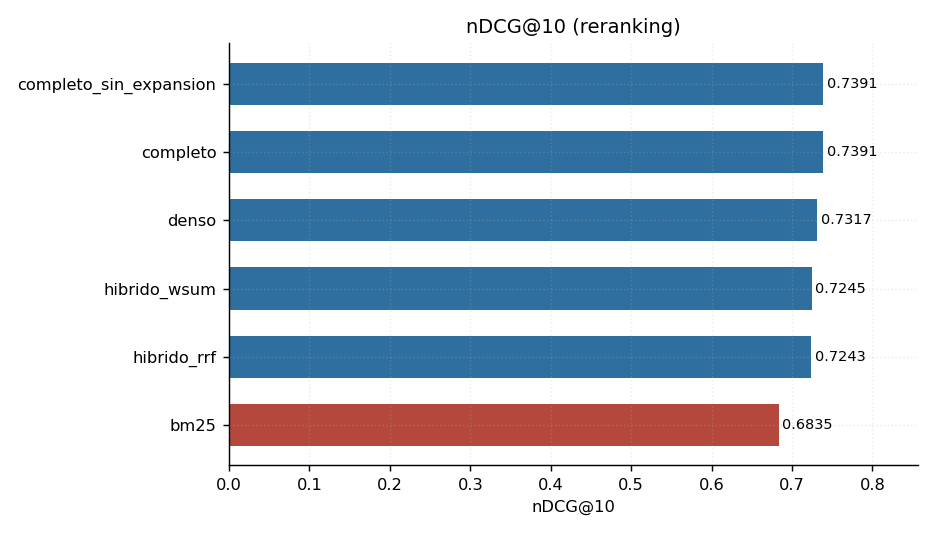

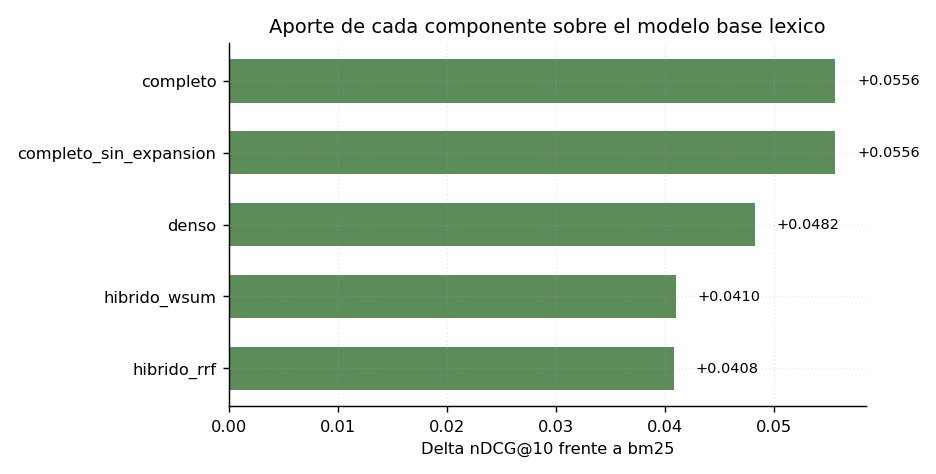

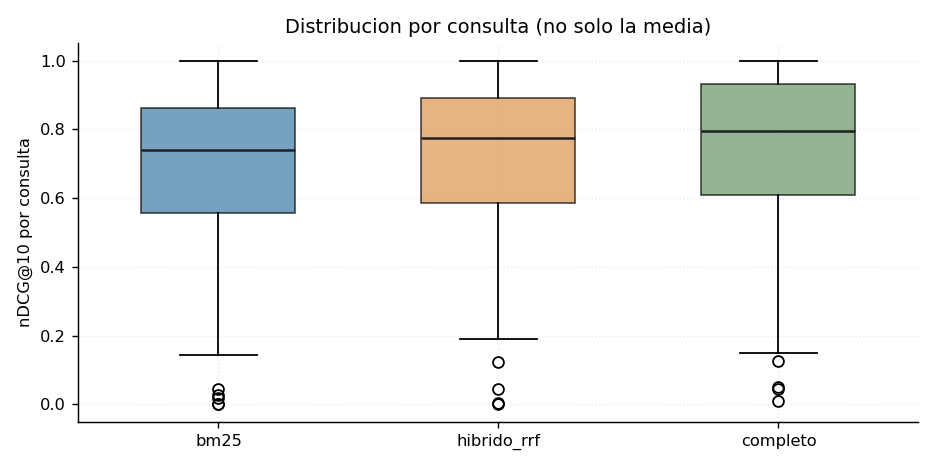

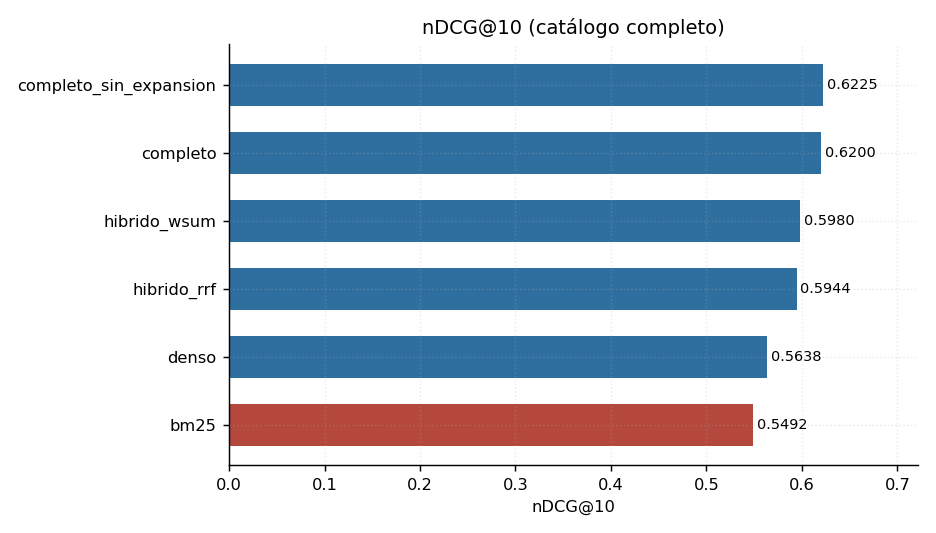

In [16]:
#@title 6.4 · Figuras
from voiceshop.report import (make_all_figures, plot_ir_comparison,
                              plot_ablation_delta, plot_ndcg_distribution)
from IPython.display import Image, display

for f in make_all_figures(ir_result=IR_RERANK, cfg=CFG):
    display(Image(f))
plot_ir_comparison(IR_CATALOGO.tabla, cfg=CFG,
                   titulo="nDCG@10 (catálogo completo)", slug="catalogo")
display(Image(str(CFG.paths.figures / "ir_ndcg10_catalogo.png")))

In [17]:
#@title 6.5 · Análisis cualitativo: dónde gana y dónde pierde
from voiceshop.ir_eval import qualitative_examples
from voiceshop.utils import write_json

CUAL = qualitative_examples(IR_RERANK, BUNDLE, sistema="completo",
                            baseline="bm25", n=5)
write_json(CFG.paths.results / "ir_reranking_cualitativo.json", CUAL)

print("CINCO ACIERTOS (mayor ganancia sobre BM25)\n" + "-"*58)
for e in CUAL["aciertos"]:
    print(f"  «{e['consulta'][:48]:48s}»  Δ={e['delta_ndcg']:+.3f}  "
          f"({e['ndcg_bm25']:.3f} → {e['ndcg_completo']:.3f})")

print("\nCINCO RETROCESOS (el sistema empeora frente a BM25)\n" + "-"*58)
for e in CUAL["retrocesos"]:
    print(f"  «{e['consulta'][:48]:48s}»  Δ={e['delta_ndcg']:+.3f}  "
          f"({e['ndcg_bm25']:.3f} → {e['ndcg_completo']:.3f})")

print("\nCINCO FALLOS ABSOLUTOS (nDCG más bajo del sistema completo)\n" + "-"*58)
for e in CUAL["fallos_absolutos"]:
    print(f"  «{e['consulta'][:48]:48s}»  nDCG={e['ndcg']:.3f}")

CINCO ACIERTOS (mayor ganancia sobre BM25)
----------------------------------------------------------
  «radiador sin aceite                             »  Δ=+0.663  (0.143 → 0.806)
  «4patas sin ruedas 40x30                         »  Δ=+0.613  (0.000 → 0.613)
  «shark                                           »  Δ=+0.613  (0.000 → 0.613)
  «panasonic lumix fz82                            »  Δ=+0.603  (0.026 → 0.629)
  «gran diver invicta                              »  Δ=+0.576  (0.424 → 1.000)

CINCO RETROCESOS (el sistema empeora frente a BM25)
----------------------------------------------------------
  «pinza moto casco                                »  Δ=-0.489  (1.000 → 0.510)
  «anillos hombre sello de oro solitario           »  Δ=-0.410  (0.743 → 0.333)
  «plancha vertical vapor sin cable                »  Δ=-0.353  (0.849 → 0.496)
  «genie la loca                                   »  Δ=-0.301  (0.555 → 0.254)
  «reina roja juan gomez jurado                    »  Δ=-0.247  (0

In [18]:
#@title 6.6 · nDCG separado por consultas con negación
from voiceshop.ir_eval import split_por_negacion
from voiceshop.utils import write_json

# BM25 no modela la negación: «funda sin tapa» y «funda con tapa» comparten
# todos los términos informativos. Si una parte apreciable de las consultas
# la lleva, el promedio global esconde un sesgo sistemático.
NEG_A = split_por_negacion(IR_RERANK, BUNDLE, split="test")
NEG_B = split_por_negacion(IR_CATALOGO, BUNDLE, split="test")

print(f"Consultas de test con negación: "
      f"{NEG_A.attrs['porcentaje_con_negacion']} %  "
      f"(«sin», «no», «nada», «excepto», «salvo», «menos», «ni»)\n")
print("PROTOCOLO A — re-ranking de candidatos anotados")
display(NEG_A)
print("\nPROTOCOLO B — catálogo completo")
display(NEG_B)

write_json(CFG.paths.results / "ir_negacion.json",
           {"protocolo_a": NEG_A.to_dict(orient="records"),
            "protocolo_b": NEG_B.to_dict(orient="records"),
            "porcentaje_con_negacion": NEG_A.attrs["porcentaje_con_negacion"]})

peor = NEG_B.sort_values("brecha").iloc[0]
print(f"\nMayor brecha en el catálogo completo: {peor['sistema']} pierde "
      f"{abs(peor['brecha']):.3f} de nDCG cuando hay negación.")

Consultas de test con negación: 19.5 %  («sin», «no», «nada», «excepto», «salvo», «menos», «ni»)

PROTOCOLO A — re-ranking de candidatos anotados


,sistema,n_con_negacion,n_sin_negacion,ndcg_con_negacion,ndcg_sin_negacion,brecha
4,completo,43,177,0.6855,0.7521,-0.0666
5,completo_sin_expansion,43,177,0.6855,0.7521,-0.0666
0,bm25,43,177,0.6052,0.7025,-0.0973
1,denso,43,177,0.6526,0.7510,-0.0984
3,hibrido_wsum,43,177,0.6418,0.7446,-0.1028
2,hibrido_rrf,43,177,0.6371,0.7455,-0.1084



PROTOCOLO B — catálogo completo


,sistema,n_con_negacion,n_sin_negacion,ndcg_con_negacion,ndcg_sin_negacion,brecha
4,completo,43,177,0.5797,0.6298,-0.0501
5,completo_sin_expansion,43,177,0.5797,0.6330,-0.0533
0,bm25,43,177,0.5052,0.5599,-0.0547
2,hibrido_rrf,43,177,0.5443,0.6065,-0.0623
3,hibrido_wsum,43,177,0.5357,0.6131,-0.0774
1,denso,43,177,0.4816,0.5838,-0.1023



Mayor brecha en el catálogo completo: denso pierde 0.102 de nDCG cuando hay negación.


In [19]:
#@title 6.7 · Ablación de campos del texto indexado (≈3 min)
from voiceshop.ir_eval import ablacion_de_campos

# Pregunta: ¿merece la pena añadir el siguiente campo al texto que se indexa?
# Se mide sobre BM25 y el catálogo completo. Es deliberado: reindexar el
# bi-encoder cinco veces costaría más de una hora de GPU, y el sistema léxico
# es el único que lee el texto literalmente, así que es donde el campo que se
# añade se nota sin intermediarios. El informe declara ese alcance.
ABLACION_CAMPOS = ablacion_de_campos(BUNDLE, cfg=CFG, split="test", k=10)
display(ABLACION_CAMPOS)
write_json(CFG.paths.results / "ir_ablacion_campos.json",
           ABLACION_CAMPOS.to_dict(orient="records"))

mejor = ABLACION_CAMPOS.loc[ABLACION_CAMPOS["ndcg@10"].idxmax()]
print(f"\nMejor composición: {mejor['composicion']} "
      f"(nDCG@10 = {mejor['ndcg@10']:.4f}, {mejor['chars_medios']} caracteres "
      f"de media por documento).")
print("Si añadir un campo no sube el nDCG, solo alarga el documento y diluye "
      "la señal del título: ese es el criterio para dejarlo fuera.")

01:13:27 | INFO    | voiceshop          |   ablacion de campos 'solo_titulo': nDCG@10=0.5600
01:13:29 | INFO    | voiceshop          |   ablacion de campos 'titulo_marca': nDCG@10=0.5643
01:13:32 | INFO    | voiceshop          |   ablacion de campos 'titulo_marca_color': nDCG@10=0.5658
01:13:38 | INFO    | voiceshop          |   ablacion de campos 'titulo_marca_color_vinetas': nDCG@10=0.5498
01:13:44 | INFO    | voiceshop          |   ablacion de campos 'completo': nDCG@10=0.5585


,composicion,campos,ndcg@10,delta_vs_anterior,chars_medios
0,solo_titulo,titulo,0.5600,NaN,116
1,titulo_marca,titulo+marca,0.5643,0.0043,133
2,titulo_marca_color,titulo+marca+color,0.5658,0.0015,144
3,titulo_marca_color_vinetas,titulo+marca+color+vinetas,0.5498,-0.0160,657
4,completo,titulo+marca+color+vinetas+descripcion,0.5585,0.0087,773



Mejor composición: titulo_marca_color (nDCG@10 = 0.5658, 144 caracteres de media por documento).
Si añadir un campo no sube el nDCG, solo alarga el documento y diluye la señal del título: ese es el criterio para dejarlo fuera.


---
## 7. Voz: referencia, ASR y TTS con clonación

### Grabación de referencia

XTTS-v2 clona el timbre a partir de un **único WAV de 6–30 s**. Requisitos:

* voz **propia o autorizada** del grupo (lo exige el enunciado);
* español, habla continua, sin música ni ruido de fondo;
* nivel entre −30 y −10 dBFS.

> **Los textos sintetizados deben ser distintos de los de la referencia.** El
> código lo comprueba: `TTS.synthesize` lanza error si coinciden.

In [22]:
#@title 7.1 · Grabar (o subir) la voz de referencia
from voiceshop.audio_io import (record_microphone, check_reference_voice, play,
                                in_colab)
from pathlib import Path

MODO_REFERENCIA = "grabar"  #@param ["grabar", "subir", "existente"]
SEGUNDOS = 15               #@param {type:"slider", min:8, max:30, step:1}

REF_WAV = CFG.paths.reference_voice / "voz_referencia.wav"

if MODO_REFERENCIA == "grabar":
    print("Lea en voz alta y con naturalidad, por ejemplo:\n")
    print('  "Mi nombre es ... y estoy grabando la voz de referencia para el')
    print('   laboratorio cuatro del curso de aprendizaje profundo. Hablo en')
    print('   español, a ritmo normal, para que el modelo capture mi timbre."\n')
    record_microphone(REF_WAV, seconds=SEGUNDOS,
                      sr=CFG.speech.reference_sample_rate)
elif MODO_REFERENCIA == "subir" and in_colab():
    from google.colab import files
    subidos = files.upload()
    origen = Path(next(iter(subidos)))
    if origen.suffix.lower() != ".wav":
        from voiceshop.audio_io import decode_webm_to_wav
        decode_webm_to_wav(origen, REF_WAV,
                           sr=CFG.speech.reference_sample_rate)
    else:
        decode_webm_to_wav(origen, REF_WAV,
                           sr=CFG.speech.reference_sample_rate)

INFO_REF = check_reference_voice(REF_WAV)
print(f"\n{INFO_REF}")
assert INFO_REF["duracion_s"] > 3, "La grabación es demasiado corta."
play(REF_WAV)

# Guarde aquí lo que dijo: sirve para verificar que el TTS genera texto distinto.
TEXTO_REFERENCIA = "Mi nombre es Henry y estoy grabando la voz de referencia."  #@param {type:"string"}

# Lo caro de recomputar, a Drive (no hace nada si se omitió la 2.3).
try:
    respaldar(verboso=False)
    print("  respaldado en Drive")
except NameError:
    pass

Lea en voz alta y con naturalidad, por ejemplo:

  "Mi nombre es ... y estoy grabando la voz de referencia para el
   laboratorio cuatro del curso de aprendizaje profundo. Hablo en
   español, a ritmo normal, para que el modelo capture mi timbre."



<IPython.core.display.Javascript object>

01:17:06 | INFO    | voiceshop          | Grabando hasta 15 s (pulse 'Detener' para cortar antes)...

{'ruta': '/content/Laboratorio4/assets/audio_ref/voz_referencia.wav', 'duracion_s': 14.1, 'sample_rate': 16000, 'nivel_dbfs': np.float64(-25.0), 'apta': True, 'avisos': []}


  respaldado en Drive


In [23]:
#@title 7.2 · Cargar ASR y TTS, y medir la latencia de carga (fría)
from voiceshop.asr import ASR
from voiceshop.tts import TTS
from voiceshop.utils import StageTimings

TIEMPOS_FRIOS = StageTimings()

ASR_MODEL = ASR(CFG)
ASR_MODEL.load(timings=TIEMPOS_FRIOS)

TTS_MODEL = TTS(CFG)
TTS_MODEL.load(timings=TIEMPOS_FRIOS)
TTS_MODEL.set_reference(REF_WAV, reference_text=TEXTO_REFERENCIA)

print(f"\nMotor TTS   : {TTS_MODEL.engine}  (clona voz: {TTS_MODEL.clones})")
if not TTS_MODEL.clones:
    print("  AVISO: XTTS no cargó; se usa MMS-TTS SIN clonación. Revise la §1.2.")
print(f"\nCarga de modelos: {TIEMPOS_FRIOS.to_dict()['carga_modelos_s']}")
print(f"VRAM: {gpu_memory_report()}")

01:17:45 | INFO    | voiceshop          | Bibliotecas CUDA publicadas para CTranslate2: libcublasLt.so.12, libcublas.so.12, libcudnn.so.9
01:17:45 | INFO    | voiceshop          | Cargando faster-whisper large-v3 (cuda, int8_float16)
01:18:40 | INFO    | voiceshop          | ASR listo en 55.0 s (backend=faster_whisper)
01:18:40 | INFO    | voiceshop          | Cargando XTTS-v2 en cuda...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 255), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 255), got 50256. This may result in unexpected behavior.
[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 607), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 607), got 50256. This may result in unexpected behavior.


01:20:02 | INFO    | voiceshop          | TTS listo en 82.2 s (motor=xtts_v2, clona=True)

Motor TTS   : xtts_v2  (clona voz: True)

Carga de modelos: {'carga_asr': 55.0491, 'carga_tts': 82.2356}
VRAM: {'total_gb': 14.56, 'libre_gb': 10.15, 'reservada_gb': 2.81, 'asignada_gb': 2.8}


In [24]:
#@title 7.3 · Prueba de clonación: sintetizar un texto nuevo
TEXTO_PRUEBA = ("Buenas tardes. Encontré tres audífonos inalámbricos dentro de "
                "su presupuesto. El primero cuesta ciento veinte soles y tiene "
                "muy buena valoración. ¿Desea que lo agregue al carrito?")

salida = TTS_MODEL.synthesize(TEXTO_PRUEBA,
                              CFG.paths.audio / "prueba_clonacion.wav")
print(salida.to_dict())
print("\nReferencia (su voz original):"); play(REF_WAV)
print("Sintetizada (texto NUEVO, mismo timbre):"); play(salida.path)

{'ruta': '/content/Laboratorio4/results/audio/prueba_clonacion.wav', 'texto': 'Buenas tardes. Encontré tres audífonos inalámbricos dentro de su presupuesto. El primero cuesta ciento veinte soles y tiene muy buena valoración. ¿Desea que lo agregue al carrito?', 'duracion_s': 17.09, 'motor': 'xtts_v2', 'clonada': True, 'referencia': '/content/Laboratorio4/assets/audio_ref/voz_referencia.wav', 'rtf': 0.665}

Referencia (su voz original):


Sintetizada (texto NUEVO, mismo timbre):


In [25]:
#@title 7.4 · Calidad de la voz: inteligibilidad y semejanza
from voiceshop.tts import intelligibility, SpeakerSimilarity

intel = intelligibility(salida.path, TEXTO_PRUEBA, ASR_MODEL)
print("INTELIGIBILIDAD (bucle TTS → ASR)")
print(f"  pedido     : {intel['texto_esperado'][:70]}...")
print(f"  reconocido : {intel['texto_reconocido'][:70]}...")
print(f"  WER = {intel['wer']:.3f} · CER = {intel['cer']:.3f} · "
      f"inteligible = {intel['inteligible']}")

SIM = SpeakerSimilarity().load()
techo = SIM.similarity(REF_WAV, REF_WAV)
obtenida = SIM.similarity(REF_WAV, salida.path)
print(f"\nSEMEJANZA DE LOCUTOR ({SIM.backend})")
print(f"  techo (referencia consigo misma) : {techo:.4f}")
print(f"  voz clonada vs referencia        : {obtenida:.4f}")
print("  Con ECAPA, > 0.70 suele indicar el mismo locutor.")

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


INTELIGIBILIDAD (bucle TTS → ASR)
  pedido     : Buenas tardes. Encontré tres audífonos inalámbricos dentro de su presu...
  reconocido : Buenas tardes, encontré 3 audífonos inalámbricos dentro de su presupue...
  WER = 0.111 · CER = 0.108 · inteligible = True


hyperparams.yaml:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


embedding_model.ckpt: reconstructing file:   0%|          |  0.00B / 83.3MB            

embedding_model.ckpt: downloading bytes:           |  0.00B            

... (5 outputs left out)

INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


label_encoder.txt:   0%|          | 0.00/129k [00:00<?, ?B/s]

INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder



SEMEJANZA DE LOCUTOR (ecapa)
  techo (referencia consigo misma) : 1.0000
  voz clonada vs referencia        : 0.6969
  Con ECAPA, > 0.70 suele indicar el mismo locutor.


### 7.5 · Cómo se lee la semejanza

Comparar la referencia **consigo misma** da 1.0 por construcción: es una
tautología, no un techo. A su lado cualquier cifra parece pobre. Las cotas
informativas son otras dos:

| Cota | Qué es | Qué dice |
|---|---|---|
| **Suelo** | semejanza con una voz que no es la del usuario | cuánto puntúa un impostor con este medidor |
| **Techo humano** | dos grabaciones *distintas* del mismo locutor | el máximo al que un clon puede aspirar, porque incluye la variabilidad natural entre tomas |

El umbral de 0.70 de la literatura ECAPA se fija sobre verificación de
locutor con habla limpia. Lo reportamos, pero la lectura honesta es la
posición relativa del clon entre suelo y techo humano.

> La segunda toma es **opcional**. Si no la graba, el informe lo dice en lugar
> de rellenar el hueco con el techo trivial.

In [28]:
#@title 7.5 · Suelo y techo humano de la semejanza
from voiceshop.tts import similarity_frame
from voiceshop.audio_io import record_microphone, in_colab

SEGUNDA_TOMA = "grabar"  #@param ["grabar", "omitir"]
SEGUNDOS_2 = 10          #@param {type:"slider", min:6, max:20, step:1}

REF_WAV_2 = None
if SEGUNDA_TOMA == "grabar" and in_colab():
    REF_WAV_2 = CFG.paths.reference_voice / "voz_referencia_2.wav"
    print("Lea un texto DISTINTO del de la referencia, con naturalidad.")
    print("Sirve para medir cuanto se parece usted a si mismo entre tomas.")
    print()
    record_microphone(REF_WAV_2, seconds=SEGUNDOS_2,
                      sr=CFG.speech.reference_sample_rate)

# Voz impostora: el mismo texto con OTRO locutor, para fijar el suelo.
VOZ_IMPOSTORA = TTS_MODEL.synthesize_other_speaker(
    TEXTO_PRUEBA, CFG.paths.audio / "voz_impostora.wav")

MARCO = similarity_frame(SIM, REF_WAV, salida.path,
                         impostor_wav=VOZ_IMPOSTORA,
                         second_reference_wav=REF_WAV_2)
print(f"\nMARCO DE SEMEJANZA ({MARCO['backend']})")
print(f"  suelo (otra voz)        : {MARCO['suelo']}")
print(f"  clon vs referencia      : {MARCO['obtenida']}")
print(f"  techo humano (2.a toma) : {MARCO['techo_humano']}")
print(f"  posicion relativa       : {MARCO['posicion_relativa']}  (0 = impostor, 1 = techo)")
print(f"  supera el umbral 0.70   : {MARCO['mismo_locutor_umbral']}")
for aviso in MARCO["avisos"]:
    print(f"  AVISO: {aviso}")

write_json(CFG.paths.results / "marco_semejanza.json", MARCO)
if VOZ_IMPOSTORA:
    print("\nVoz impostora (otro locutor):"); play(VOZ_IMPOSTORA)

Lea un texto DISTINTO del de la referencia, con naturalidad.
Sirve para medir cuanto se parece usted a si mismo entre tomas.



<IPython.core.display.Javascript object>

01:25:11 | INFO    | voiceshop          | Grabando hasta 10 s (pulse 'Detener' para cortar antes)...

MARCO DE SEMEJANZA (ecapa)
  suelo (otra voz)        : 0.1015
  clon vs referencia      : 0.6969
  techo humano (2.a toma) : 0.7945
  posicion relativa       : 0.8592  (0 = impostor, 1 = techo)
  supera el umbral 0.70   : False

Voz impostora (otro locutor):


---
## 8. Agente: demostración por texto

### Protocolo de herramientas

En cada paso el LLM emite **un único objeto JSON**:

```json
{"razonamiento": "...", "accion": "buscar_productos",
 "argumentos": {"consulta": "audífonos bluetooth", "precio_max": 200}}
```

El parser tolera bloques ```` ```json ````, comas colgantes, comillas
tipográficas y argumentos aplanados, y reintenta con un mensaje de reparación.

### Lo que **no** decide el LLM

| Control | Dónde vive | Qué evita |
|---|---|---|
| Confirmación explícita | `policy.detect_confirmation` | comprar por un «sí, pero cambia…» |
| Transcripción dudosa | `policy.needs_transcript_confirmation` | comprar 12 cuando dijo 2 |
| Cantidad, stock, presupuesto | `store.py` | pedidos imposibles |
| Atomicidad e idempotencia | `store.place_order` | pedidos parciales o duplicados |
| Cifras de la respuesta | `grounding.verify_response` | precios inventados |

In [29]:
#@title 8.1 · Montar el agente
from voiceshop.agent import ShoppingAgent
from voiceshop.llm import LocalLLM

LLM = LocalLLM(CFG)
LLM.load(timings=TIEMPOS_FRIOS)

AGENTE = ShoppingAgent(STORE, RETRIEVER, llm=LLM, asr=ASR_MODEL, tts=TTS_MODEL,
                       cfg=CFG, session_id="demo-texto")
print(f"Agente listo. Herramientas: {list(AGENTE.registry)}")
print(f"\nCarga total de modelos: "
      f"{TIEMPOS_FRIOS.to_dict()['total_carga_s']:.1f} s")
print(f"VRAM: {gpu_memory_report()}")

01:25:41 | INFO    | voiceshop          | Cargando LLM Qwen/Qwen2.5-3B-Instruct (4bit=True, cuda=True)...


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

01:37:43 | INFO    | voiceshop          | LLM listo en 722.4 s. VRAM: {'total_gb': 14.56, 'libre_gb': 8.0, 'reservada_gb': 4.88, 'asignada_gb': 4.8}
Agente listo. Herramientas: ['buscar_productos', 'ver_detalle', 'comparar_productos', 'agregar_al_carrito', 'actualizar_cantidad', 'quitar_del_carrito', 'ver_carrito', 'fijar_presupuesto', 'registrar_preferencia', 'cotizar', 'confirmar_pedido', 'buscar_alternativa', 'pedir_aclaracion', 'responder']

Carga total de modelos: 859.6 s
VRAM: {'total_gb': 14.56, 'libre_gb': 8.0, 'reservada_gb': 4.88, 'asignada_gb': 4.8}


In [30]:
#@title 8.2 · Diálogo completo de compra (4 turnos)
STORE.restore(SNAPSHOT_LIMPIO)
AGENTE.reset(session_id="demo-texto")

DIALOGO = [
    "Hola, necesito unos audífonos bluetooth y una mochila para laptop. "
    "Mi presupuesto máximo es de 600 soles.",
    "Me quedo con la primera opción de cada uno. Agrégalas al carrito.",
    "¿Cuánto sería el total?",
    "Sí, confirmo el pedido.",
]

for i, texto in enumerate(DIALOGO, 1):
    print(f"\n{'='*72}\nTURNO {i}\nUSUARIO   : {texto}")
    r = AGENTE.handle_turn(texto)
    for c in r.tool_calls:
        args = {k: v for k, v in c["argumentos"].items() if k != "consulta"}
        ok = c["resultado"].get("ok")
        err = c["resultado"].get("error", "")
        print(f"  [{c['paso']}] {c['herramienta']}({args}) → "
              f"{'ok' if ok else 'ERROR ' + str(err)}")
    print(f"ASISTENTE : {r.response_text}")
    print(f"  confirmó={r.confirmed} ({r.confirmation_reason}) · "
          f"verificado={r.grounding['ok']} · "
          f"incumplimientos={len(r.violations)} · "
          f"{r.timings.total:.2f} s")

print(f"\n{'='*72}\nESTADO FINAL")
print(f"  Pedidos   : {[o['order_id'] for o in STORE.orders_of('demo-texto')]}")
for o in STORE.orders_of("demo-texto"):
    print(f"  Total     : S/ {o['total']:.2f}")
    for l in o["lineas"]:
        print(f"              {l['cantidad']} × {l['titulo'][:50]}")
print(f"  Memoria   :\n{AGENTE.state.memory_block()}")


TURNO 1
USUARIO   : Hola, necesito unos audífonos bluetooth y una mochila para laptop. Mi presupuesto máximo es de 600 soles.
  [0] fijar_presupuesto({'monto': 600.0}) → ok
  [1] buscar_productos({'precio_max': 600.0, 'k': 3}) → ok
  [2] ver_detalle({'product_id': 'B07Q79C2D8'}) → ok
  [3] buscar_productos({'precio_max': 600.0, 'k': 3}) → ok
  [4] ver_detalle({'product_id': 'B07FDLS3NH'}) → ok
  [5] cotizar({}) → ERROR CARRITO_VACIO
  [6] agregar_al_carrito({'product_id': 'B07Q79C2D8', 'cantidad': 1}) → ERROR ACCION_NO_SOLICITADA
  [7] agregar_al_carrito({'product_id': 'B07FDLS3NH', 'cantidad': 1}) → ERROR ACCION_NO_SOLICITADA
  [8] cotizar({}) → ERROR CARRITO_VACIO
ASISTENTE : Encontre WENIG Mochila Antirrobo Impermeable,Mochila Portatil 1… a 62.25 soles; TARION M-02 Mochila Cámara Impermeable Mochila Fotogra… a 306.47 soles; YAMTION Mochila para Portátil con USB Puerto de Carga … a 19.23 soles. Cual le interesa?
  confirmó=False (sin afirmacion explicita) · verificado=True · incumpl

In [31]:
#@title 8.3 · Ambigüedad, agotado y confirmación tramposa
casos = [
    ("AMBIGÜEDAD", "Quiero comprar algo para la casa, lo que esté bien."),
    ("CONFIRMACIÓN TRAMPOSA", "Sí, pero mejor cambia la cantidad a tres."),
]
for titulo, texto in casos:
    STORE.restore(SNAPSHOT_LIMPIO)
    AGENTE.reset(session_id=f"demo-{titulo[:6]}")
    print(f"\n{'='*72}\n{titulo}\nUSUARIO   : {texto}")
    r = AGENTE.handle_turn(texto)
    print(f"ASISTENTE : {r.response_text}")
    print(f"  pidió aclaración = {r.asked_clarification} · "
          f"confirmó = {r.confirmed} ({r.confirmation_reason})")
    print(f"  pedidos registrados = {len(STORE.orders_of(AGENTE.state.session_id))}")


AMBIGÜEDAD
USUARIO   : Quiero comprar algo para la casa, lo que esté bien.
ASISTENTE : Con mucho gusto, pero necesito algo mas concreto para buscar bien. Que tipo de producto tiene en mente, y tiene algun presupuesto?
  pidió aclaración = True · confirmó = False (sin afirmacion explicita)
  pedidos registrados = 0

CONFIRMACIÓN TRAMPOSA
USUARIO   : Sí, pero mejor cambia la cantidad a tres.
ASISTENTE : Encontre Ranma 1/2 - Box 1 [Blu-ray] a 648.05 soles; El secreto de la orquídea (Best Seller) a 53.10 soles; Baby Gift Set - Neutral Hamper Full of Baby Products i… a 1649.38 soles. Cual le interesa?
  pidió aclaración = True · confirmó = False (afirmacion 'si' acompanada de una peticion de cambio ('pero'))
  pedidos registrados = 0


---
## 9. Agente: demostración por voz

Turno completo: **grabar → transcribir → razonar → actuar → responder hablando**,
con la latencia medida *desde que termina la grabación*.

In [33]:
#@title 9.1 · Turno por voz en vivo
STORE.restore(SNAPSHOT_LIMPIO)
AGENTE.reset(session_id="demo-voz")

SEGUNDOS_TURNO = 10  #@param {type:"slider", min:5, max:20, step:1}

print("Diga algo como: «Busco unos audífonos bluetooth de menos de "
      "doscientos soles»\n")
audio_usuario = CFG.paths.audio / "demo_voz_turno1.wav"
record_microphone(audio_usuario, seconds=SEGUNDOS_TURNO)
play(audio_usuario)

r = AGENTE.handle_voice_turn(audio_usuario,
                             speak_to=CFG.paths.audio / "demo_voz_resp1.wav")

print(f"\nTRANSCRIPCIÓN : {r.transcription['texto']}")
print(f"  logprob medio = {r.transcription['logprob_medio']:.3f} · "
      f"baja confianza = {r.transcription['baja_confianza']}")
print(f"  cantidades detectadas = {r.transcription['cantidades']} · "
      f"importes = {r.transcription['importes']}")
print(f"\nHERRAMIENTAS  : {[c['herramienta'] for c in r.tool_calls]}")
print(f"RESPUESTA     : {r.response_text}")
print(f"\n{r.timings.pretty()}")
if r.audio_out:
    play(r.audio_out)

Diga algo como: «Busco unos audífonos bluetooth de menos de doscientos soles»



<IPython.core.display.Javascript object>

01:43:01 | INFO    | voiceshop          | Grabando hasta 10 s (pulse 'Detener' para cortar antes)...



TRANSCRIPCIÓN : Busco unos audífonos Bluetooth de menos de 200 soles.
  logprob medio = -0.086 · baja confianza = False
  cantidades detectadas = [] · importes = [200.0]

HERRAMIENTAS  : ['fijar_presupuesto', 'buscar_productos', 'ver_carrito', 'agregar_al_carrito', 'ver_detalle', 'ver_carrito', 'agregar_al_carrito', 'ver_detalle', 'cotizar']
RESPUESTA     : Encontre Xiaomi Redmi AirDots Bluetooth 5.0 Auriculares, audífo… a 105.18 soles; EJEAS V6 Pro BT Interphone 1200M Bluetooth Motocicleta… a 42.21 soles; Avantree 40 Horas aptX Hi-Fi Auriculares Diadema Bluet… a 16.41 soles. Cual le interesa?

Latencia por etapa (consulta tibia):
  asr_transcripcion        0.689 s
  llm_decision            32.994 s
  recuperacion_bm25        0.001 s
  recuperacion_densa       0.021 s
  reranking                0.276 s
  filtros_negocio          0.000 s
  verificacion             0.001 s
  tts_sintesis            14.477 s
  total_extremo_a_extremo  48.486 s
  TOTAL                   48.486 s


In [34]:
#@title 9.2 · Segundo turno por voz (continúa la conversación)
print("Continúe, por ejemplo: «Agrega dos unidades del primero al carrito»\n")
audio2 = CFG.paths.audio / "demo_voz_turno2.wav"
record_microphone(audio2, seconds=SEGUNDOS_TURNO)

r2 = AGENTE.handle_voice_turn(audio2,
                              speak_to=CFG.paths.audio / "demo_voz_resp2.wav")
print(f"\nTRANSCRIPCIÓN : {r2.transcription['texto']}")
print(f"HERRAMIENTAS  : {[c['herramienta'] for c in r2.tool_calls]}")
print(f"RESPUESTA     : {r2.response_text}")
print(f"CARRITO       : {STORE.view_cart('demo-voz')}")
print(f"\n{r2.timings.pretty()}")
if r2.audio_out:
    play(r2.audio_out)

Continúe, por ejemplo: «Agrega dos unidades del primero al carrito»



<IPython.core.display.Javascript object>

01:44:05 | INFO    | voiceshop          | Grabando hasta 10 s (pulse 'Detener' para cortar antes)...

TRANSCRIPCIÓN : agrega 2 unidades del primero al carrito
HERRAMIENTAS  : ['agregar_al_carrito', 'responder']
RESPUESTA     : Resultados de la adición: Anade 2 unidades del producto a 105.18 soles, pero sobrepasa el presupuesto. ¿Le gustaría bajar la cantidad o elegir algo más barato?
CARRITO       : {'ok': True, 'lineas': [], 'n_lineas': 0, 'subtotal': 0.0, 'moneda': 'PEN'}

Latencia por etapa (consulta tibia):
  asr_transcripcion        0.629 s
  llm_decision            11.833 s
  verificacion             0.001 s
  tts_sintesis             8.071 s
  total_extremo_a_extremo  20.560 s
  TOTAL                   20.560 s


---
## 10. Los escenarios operativos

Veinte escenarios cubren lo que pide el enunciado. Cuatro más (E21–E24) son un **conjunto de control** que no se usó para corregir el agente; el porqué está más abajo.

Cada escenario:

1. restaura la tienda a su estado de semilla;
2. resuelve sus **anclas** (consulta + requisito: *con stock*, *agotado*,
   *caro*…) contra el catálogo real y fuerza el stock declarado — así es
   reproducible sin codificar identificadores de ESCI a mano;
3. ejecuta los turnos aplicando los eventos declarados (p. ej. «el stock cae a 1
   justo antes de confirmar»);
4. evalúa aserciones automáticas y guarda operaciones, estado final y audios.

| Categoría | Escenarios |
|---|---|
| Compra completa | E01, E20 |
| Aclaración por ambigüedad | E02 |
| Cambio de cantidad/preferencia | E03, E16 |
| Producto agotado | E04, E14 |
| Corrección de transcripción | E05 |
| Cambio de stock concurrente | E06 |
| Presupuesto | E07, E15 |
| Comparación | E08 |
| Validación de cantidades | E09, E10 |
| Fuera de catálogo | E11 |
| Cancelación | E12 |
| Memoria | E13 |
| Confirmación ambigua | E17 |
| Límites de stock | E18, E19 |
| **Fuera de tema** (control) | **E21** |
| **Atributo desconocido** (control) | **E22** |
| **Ambigüedad de categoría** (control) | **E23** |
| **Negación en la consulta** (control) | **E24** |

### Qué se ajustó mirando estos escenarios, y qué no

El enunciado prohíbe ajustar el sistema con las consultas de evaluación. En
recuperación se respeta sin matices: el ajuste usa `dev` y `test` se mide una
sola vez. **En el agente no fue así, y conviene decirlo con todas las letras.**

Una primera ejecución de la batería de voz falló en 5 de 6 casos. El
diagnóstico de esos fallos —y solo de esos— motivó siete cambios en el código:
confirmación después de cambiar una cantidad, carrito idempotente, corte de
bucles, resolución de referencias a producto, aviso de agotado, compuerta de
mutación del carrito y detección del «si» condicional. **E01, E03, E04, E05 y
E20 informaron esos cambios**, así que sus resultados miden un sistema
corregido contra los casos que lo corrigieron, y están sesgados al alza.

Por eso se añadieron **E21 a E24**, escritos después de congelar el código y a
partir de las recomendaciones de la asesoría, no de ningún fallo observado.
Son el conjunto de control: la única medida de este agente sobre casos que
nunca vio. La tabla de la celda 10.4 los reporta aparte, y la diferencia entre
ambos grupos es la estimación honesta del sesgo.

In [35]:
#@title 10.1 · Cobertura declarada
import pandas as pd
from voiceshop.scenarios import SCENARIOS, coverage_table, voice_scenarios

COB = pd.DataFrame(coverage_table())
display(COB)
print(f"\nTotal: {len(SCENARIOS)} escenarios · "
      f"{len(voice_scenarios())} por voz · "
      f"{sum(s.multiturno for s in voice_scenarios())} de ellos multi-turno")

,id,nombre,categoria,voz,turnos,multiturno,n_checks
0,E01,Compra dentro del presupuesto con pedido confirmado,compra_completa,True,4,True,5
1,E02,Solicitud ambigua que exige aclaracion,aclaracion,True,1,False,3
2,E03,Cambio de cantidad conservando presupuesto y preferencia,cambio_preferencia,True,4,True,5
3,E04,Producto agotado: alternativa o negativa honesta,agotado,True,2,True,3
4,E05,Correccion de la transcripcion antes de comprar,correccion_asr,True,3,True,4
5,E06,"Cambio de stock entre cotizacion y confirmacion, con reintento",stock_concurrente,True,6,True,4
6,E07,Presupuesto insuficiente para lo pedido,presupuesto,False,2,True,3
7,E08,Comparacion entre alternativas antes de decidir,comparacion,False,2,True,3
8,E09,Cantidad invalida (cero unidades),validacion,False,1,False,3
9,E10,Cantidad por encima del maximo permitido,validacion,False,2,True,2



Total: 24 escenarios · 6 por voz · 5 de ellos multi-turno


In [36]:
#@title 10.2 · Ejecutar los escenarios por texto (20 + 4 de control, ≈10 min)
from voiceshop.runner import run_all, save_results, summarize

RES_TEXTO = run_all(AGENTE, STORE, RETRIEVER, modo="texto", cfg=CFG)
RUTAS = save_results(RES_TEXTO, cfg=CFG, nombre="escenarios")
RESUMEN = summarize(RES_TEXTO)

print("\n" + "="*68)
for k, v in RESUMEN.items():
    print(f"  {k:32s} {v}")

01:48:54 | INFO    | voiceshop          | [E01] Compra dentro del presupuesto con pedido conf modo=texto exito=True (129.5s)
01:48:54 | INFO    | voiceshop          | [E02] Solicitud ambigua que exige aclaracion modo=texto exito=True (0.0s)
01:50:27 | INFO    | voiceshop          | [E03] Cambio de cantidad conservando presupuesto y  modo=texto exito=False (93.1s)
01:51:15 | INFO    | voiceshop          | [E04] Producto agotado: alternativa o negativa hone modo=texto exito=False (47.9s)
01:52:20 | INFO    | voiceshop          | [E05] Correccion de la transcripcion antes de compr modo=texto exito=True (64.2s)
01:53:13 | INFO    | voiceshop          | [E06] evento: stock de Televisor Led 24 Pulgadas HD, TD System… cambiado a 1
01:53:50 | INFO    | voiceshop          | [E06] Cambio de stock entre cotizacion y confirmaci modo=texto exito=True (90.5s)
01:54:38 | INFO    | voiceshop          | [E07] Presupuesto insuficiente para lo pedido modo=texto exito=True (47.8s)
01:55:47 | INFO    | voi

In [37]:
#@title 10.3 · Detalle por escenario
filas = []
for r in RES_TEXTO:
    filas.append({
        "id": r.scenario_id, "categoría": r.categoria,
        "éxito": "SÍ" if r.exito else "no",
        "checks": f"{sum(c['ok'] for c in r.checks)}/{len(r.checks)}",
        "incumpl.": r.n_incumplimientos, "s": round(r.segundos, 1),
        "fallidos": ", ".join(c["tipo"] for c in r.checks if not c["ok"])[:46],
    })
display(pd.DataFrame(filas))

for r in RES_TEXTO:
    if not r.exito:
        print(f"\n{'─'*68}\n{r.scenario_id} · {r.nombre}")
        for c in r.checks:
            if not c["ok"]:
                print(f"  FALLÓ {c['tipo']}: {c['detalle']}")
        for t in r.turnos:
            print(f"  U> {t['usuario'][:68]}")
            print(f"  A> {t['asistente'][:68]}")

,id,categoría,éxito,checks,incumpl.,s,fallidos
0,E01,compra_completa,SÍ,5/5,0,129.5,
1,E02,aclaracion,SÍ,3/3,0,0.0,
2,E03,cambio_preferencia,no,2/5,0,93.1,"pedido_registrado, cantidad_en_pedido, n_pedid"
3,E04,agotado,no,2/3,0,47.9,manejo_agotado
4,E05,correccion_asr,SÍ,4/4,0,64.2,
5,E06,stock_concurrente,SÍ,4/4,0,90.5,
6,E07,presupuesto,SÍ,3/3,0,47.8,
7,E08,comparacion,SÍ,3/3,0,69.2,
8,E09,validacion,SÍ,3/3,0,65.1,
9,E10,validacion,SÍ,2/2,0,99.5,



────────────────────────────────────────────────────────────────────
E03 · Cambio de cantidad conservando presupuesto y preferencia
  FALLÓ pedido_registrado: 0 pedidos
  FALLÓ cantidad_en_pedido: el producto no aparece en ningun pedido
  FALLÓ n_pedidos: esperado 1, obtenido 0
  U> Busco un teclado inalambrico negro, no mas de 250 soles en total.
  A> Encontre OMOTON Teclado Inalámbrico con USB, Teclado Español Or… a 2
  U> Agrega dos unidades del primero al carrito.
  A> El teclado fue agregado al carrito. ¿Desea agregar más productos o c
  U> Mejor que sean tres unidades, lo demas igual.
  A> El teclado fue agregado al carrito con 3 unidades. ¿Desea agregar má
  U> Si, confirmo.
  A> La cotizacion es de 94.71 soles. ¿Le gustaría confirmar el pedido?

────────────────────────────────────────────────────────────────────
E04 · Producto agotado: alternativa o negativa honesta
  FALLÓ manejo_agotado: alternativa=False error_stock=False lo_dijo=False
  U> Quiero una cafetera espresso, do

In [38]:
#@title 10.4 · Conjunto de control frente a los escenarios que informaron los parches
INFORMARON_PARCHES = {"E01", "E03", "E04", "E05", "E20"}
CONTROL = {"E21", "E22", "E23", "E24"}

filas = []
for r in RES_TEXTO:
    sid = r.scenario_id if hasattr(r, "scenario_id") else r["id"]
    exito = r.exito if hasattr(r, "exito") else r["exito"]
    checks = r.checks if hasattr(r, "checks") else r["checks"]
    if sid in CONTROL:
        grupo = "control (no visto)"
    elif sid in INFORMARON_PARCHES:
        grupo = "informo los parches"
    else:
        grupo = "resto"
    filas.append({"id": sid, "grupo": grupo, "exito": bool(exito),
                  "checks_ok": sum(1 for c in checks if c["ok"]),
                  "checks": len(checks)})

DF_GRUPOS = pd.DataFrame(filas)
resumen = (DF_GRUPOS.groupby("grupo")
           .agg(n=("id", "count"), correctos=("exito", "sum"),
                checks_ok=("checks_ok", "sum"), checks=("checks", "sum")))
resumen["% escenarios"] = (100 * resumen["correctos"] / resumen["n"]).round(1)
resumen["% checks"] = (100 * resumen["checks_ok"] / resumen["checks"]).round(1)
display(resumen)

print("Lectura: si el grupo de control rinde claramente peor que el que "
      "informo los parches, la diferencia es el sesgo de haber corregido "
      "mirando la evaluacion. Si rinde parecido, los arreglos generalizan.")
display(DF_GRUPOS[DF_GRUPOS["grupo"] != "resto"])

,n,correctos,checks_ok,checks,% escenarios,% checks
grupo,,,,,,
control (no visto),4,2,15,17,50.0,88.2
informo los parches,5,3,16,20,60.0,80.0
resto,15,12,37,42,80.0,88.1


Lectura: si el grupo de control rinde claramente peor que el que informo los parches, la diferencia es el sesgo de haber corregido mirando la evaluacion. Si rinde parecido, los arreglos generalizan.


,id,grupo,exito,checks_ok,checks
0,E01,informo los parches,True,5,5
2,E03,informo los parches,False,2,5
3,E04,informo los parches,False,2,3
4,E05,informo los parches,True,4,4
19,E20,informo los parches,True,3,3
20,E21,control (no visto),False,4,5
21,E22,control (no visto),False,3,4
22,E23,control (no visto),True,4,4
23,E24,control (no visto),True,4,4


---
## 11. Escenarios por voz y atribución de errores del ASR

Los seis escenarios por voz se ejecutan **dos veces**:

1. **por voz** — audio real → Whisper → agente;
2. **por texto** — la transcripción correcta directamente al agente.

Comparando las operaciones ejecutadas en ambas:

| Voz | Texto | Operaciones | Conclusión |
|---|---|---|---|
| falla | acierta | distintas | el fallo es **del ASR** |
| falla | acierta | iguales | el fallo es del agente ante el fraseo hablado |
| falla | falla | — | el fallo es **del agente** |

### Audio del usuario

El ejecutor busca primero `assets/audio_usuario/<ID>_t<N>.wav`. **Para la
entrega grabe ahí las voces reales** del grupo. Si no existen, sintetiza el
turno con una voz distinta de la del asistente y lo marca como `sintetizada`.

In [49]:
#@title 11.1 · (Opcional) Grabar los turnos de los escenarios por voz
#@markdown Ejecute esta celda para grabar los turnos reales. Puede saltarla:
#@markdown en ese caso los turnos se sintetizan y quedan marcados como tales.
GRABAR_ESCENARIOS = True  #@param {type:"boolean"}

if GRABAR_ESCENARIOS:
    destino = CFG.paths.assets / "audio_usuario"
    destino.mkdir(parents=True, exist_ok=True)
    for scn in voice_scenarios():
        print(f"\n{'='*68}\n{scn.id} · {scn.nombre}")
        for i, t in enumerate(scn.turnos):
            ruta = destino / f"{scn.id}_t{i+1}.wav"
            if ruta.exists():
                print(f"  turno {i+1}: ya grabado"); continue
            print(f"\n  Turno {i+1} — diga:\n    «{t.texto}»")
            if t.nota:
                print(f"    (nota: {t.nota})")
            input("  Pulse Enter y hable...")
            record_microphone(ruta, seconds=14)
    print("\nGrabaciones completas.")
else:
    print("Se usarán voces sintetizadas para los turnos del usuario.")


E01 · Compra dentro del presupuesto con pedido confirmado

  Turno 1 — diga:
    «Hola, necesito unos audifonos bluetooth y una mochila para laptop. Mi presupuesto maximo es de 600 soles.»
  Pulse Enter y hable...


<IPython.core.display.Javascript object>

02:35:08 | INFO    | voiceshop          | Grabando hasta 14 s (pulse 'Detener' para cortar antes)...

  Turno 2 — diga:
    «Me quedo con las primeras opciones que mencionaste. Agregalas al carrito, por favor.»
  Pulse Enter y hable...


<IPython.core.display.Javascript object>

02:35:30 | INFO    | voiceshop          | Grabando hasta 14 s (pulse 'Detener' para cortar antes)...

  Turno 3 — diga:
    «Cuanto seria el total?»
  Pulse Enter y hable...


<IPython.core.display.Javascript object>

... (31 outputs left out)

<IPython.core.display.Javascript object>

02:39:01 | INFO    | voiceshop          | Grabando hasta 14 s (pulse 'Detener' para cortar antes)...

  Turno 6 — diga:
    «Si, confirmo el pedido.»
    (nota: Confirmacion repetida: no debe duplicar)
  Pulse Enter y hable...


<IPython.core.display.Javascript object>

02:39:09 | INFO    | voiceshop          | Grabando hasta 14 s (pulse 'Detener' para cortar antes)...

Grabaciones completas.


In [50]:
#@title 11.2 · Ejecutar los 6 escenarios por voz + su réplica por texto (≈12 min)
from voiceshop.runner import UserVoice, run_voice_and_text
from voiceshop.utils import write_json

# Voz distinta a la del asistente para simular al usuario cuando no hay grabación.
VOZ_USUARIO = None
# Excluimos 'voz_referencia*': son tomas del propio usuario y servirian de
# techo humano, no de voz ajena.
otros = [p for p in CFG.paths.reference_voice.glob("*.wav")
         if p.resolve() != REF_WAV.resolve()
         and not p.name.startswith("voz_referencia")]
if otros:
    VOZ_USUARIO = otros[0]
    print(f"Voz de usuario simulada: {VOZ_USUARIO.name}")

UV = UserVoice(cfg=CFG, tts=TTS_MODEL, voz_usuario_wav=VOZ_USUARIO)

RES_VOZ = []
for scn in voice_scenarios():
    print(f"\n{'='*68}\n{scn.id} · {scn.nombre}")
    RES_VOZ.append(run_voice_and_text(scn, AGENTE, STORE, RETRIEVER, UV, CFG))

write_json(CFG.paths.results / "escenarios_voz.json", RES_VOZ)

filas = [{"id": r["id"], "voz_ok": r["voz"]["exito"],
          "texto_ok": r["texto"]["exito"],
          "ops_iguales": r["operaciones_iguales"],
          "WER": r["wer_medio"], "err_cant": r["errores_cantidad"],
          "err_imp": r["errores_importe"], "atribución": r["atribucion"]}
         for r in RES_VOZ]
display(pd.DataFrame(filas))

02:39:26 | WARNING | voiceshop          | Sin voz de usuario distinta: los turnos sinteticos usaran la misma voz que el asistente. Para la entrega, grabe los turnos en /content/Laboratorio4/assets/audio_usuario.

E01 · Compra dentro del presupuesto con pedido confirmado
02:39:26 | INFO    | voiceshop          | Cargando encoder denso intfloat/multilingual-e5-base en cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

02:39:35 | INFO    | voiceshop          | Cargando reranker BAAI/bge-reranker-base en cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

02:39:43 | INFO    | voiceshop          | Bibliotecas CUDA publicadas para CTranslate2: libcublasLt.so.12, libcublas.so.12, libcudnn.so.9
02:39:43 | INFO    | voiceshop          | Cargando faster-whisper large-v3 (cuda, int8_float16)
02:40:02 | INFO    | voiceshop          | ASR listo en 18.7 s (backend=faster_whisper)
02:40:03 | INFO    | voiceshop          | Cargando LLM Qwen/Qwen2.5-3B-Instruct (4bit=True, cuda=True)...


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

02:40:30 | INFO    | voiceshop          | LLM listo en 26.5 s. VRAM: {'total_gb': 14.56, 'libre_gb': 7.77, 'reservada_gb': 5.1, 'asignada_gb': 5.03}
02:41:07 | INFO    | voiceshop          | Cargando XTTS-v2 en cuda...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

02:41:30 | INFO    | voiceshop          | TTS listo en 23.5 s (motor=xtts_v2, clona=True)
02:43:19 | INFO    | voiceshop          | [E01] Compra dentro del presupuesto con pedido conf modo=voz exito=True (232.7s)
02:45:31 | INFO    | voiceshop          | [E01] Compra dentro del presupuesto con pedido conf modo=texto exito=True (132.2s)

E02 · Solicitud ambigua que exige aclaracion
02:45:38 | INFO    | voiceshop          | [E02] Solicitud ambigua que exige aclaracion modo=voz exito=True (7.1s)
02:45:38 | INFO    | voiceshop          | [E02] Solicitud ambigua que exige aclaracion modo=texto exito=True (0.0s)

E03 · Cambio de cantidad conservando presupuesto y preferencia
02:47:19 | INFO    | voiceshop          | [E03] Cambio de cantidad conservando presupuesto y  modo=voz exito=True (100.4s)
02:48:50 | INFO    | voiceshop          | [E03] Cambio de cantidad conservando presupuesto y  modo=texto exito=False (91.4s)

E04 · Producto agotado: alternativa o negativa honesta
02:49:20 | INFO   

,id,voz_ok,texto_ok,ops_iguales,WER,err_cant,err_imp,atribución
0,E01,True,True,False,0.0192,0,0,ambos_correctos
1,E02,True,True,True,0.0000,0,0,ambos_correctos
2,E03,True,False,False,0.0357,0,0,inconsistencia_revisar
3,E04,True,False,False,0.0833,0,0,inconsistencia_revisar
4,E05,True,True,False,0.0000,0,0,ambos_correctos
5,E06,True,True,False,0.0000,0,0,ambos_correctos


In [59]:
from pathlib import Path
d = CFG.paths.assets / "audio_usuario"
print(d, "->", len(list(d.glob("*.wav"))) if d.exists() else "NO EXISTE")

/content/Laboratorio4/assets/audio_usuario -> 20


In [51]:
#@title 11.3 · Transcripciones y divergencias
for r in RES_VOZ:
    print(f"\n{'='*72}\n{r['id']} · {r['nombre']}")
    print(f"  atribución: {r['atribucion']} · ops iguales: "
          f"{r['operaciones_iguales']}")
    for i, t in enumerate(r["voz"]["turnos"], 1):
        ref = t.get("texto_referencia", "")
        hip = (t.get("asr") or {}).get("texto", "(sin ASR)")
        e = t.get("errores_asr", {})
        print(f"\n  Turno {i}  [{t.get('origen_audio_usuario','?')}]")
        print(f"    dicho       : {ref[:66]}")
        print(f"    transcrito  : {hip[:66]}")
        if e:
            print(f"    WER={e['wer']:.3f} · err_cantidad={e['error_cantidad']} "
                  f"· err_importe={e['error_importe']}")
            if e["terminos_perdidos"]:
                print(f"    términos perdidos: {e['terminos_perdidos'][:5]}")
    if not r["operaciones_iguales"]:
        print(f"\n    ops por voz   : {r['operaciones_voz']}")
        print(f"    ops por texto : {r['operaciones_texto']}")


E01 · Compra dentro del presupuesto con pedido confirmado
  atribución: ambos_correctos · ops iguales: False

  Turno 1  [grabacion_humana]
    dicho       : Hola, necesito unos audifonos bluetooth y una mochila para laptop.
    transcrito  : Hola, necesito unos audífonos Bluetooth y 1 mochila para laptop. M
    WER=0.000 · err_cantidad=False · err_importe=False

  Turno 2  [grabacion_humana]
    dicho       : Me quedo con las primeras opciones que mencionaste. Agregalas al c
    transcrito  : Me quedé con las primeras opciones que mencionaste, agregalas al c
    WER=0.077 · err_cantidad=False · err_importe=False
    términos perdidos: ['quedo']

  Turno 3  [grabacion_humana]
    dicho       : Cuanto seria el total?
    transcrito  : ¿Cuánto sería el total?
    WER=0.000 · err_cantidad=False · err_importe=False

  Turno 4  [grabacion_humana]
    dicho       : Si, confirmo el pedido.
    transcrito  : Sí, confirmo el pedido.
    WER=0.000 · err_cantidad=False · err_importe=False

    o

---
## 12. Métricas de voz y latencia

* **ASR**: WER/CER globales **y** errores específicos en cantidades, importes y
  términos de producto — que son los que convierten un error de transcripción
  en una compra equivocada.
* **TTS**: inteligibilidad por bucle TTS→ASR y semejanza de locutor ECAPA,
  siempre **acotada por un techo y un suelo** (un coseno aislado no dice nada).
* **Latencia**: desde el fin de la grabación hasta que el audio puede
  reproducirse, desglosada por etapa, separando carga fría de consulta tibia.

In [52]:
#@title 12.1 · Informe de voz
from voiceshop.speech_eval import build_speech_report

INFORME_VOZ = build_speech_report(
    RES_VOZ, ASR_MODEL, reference_wav=REF_WAV,
    cold_timings=TIEMPOS_FRIOS.cold, otra_voz_wav=VOZ_IMPOSTORA,
    segunda_referencia_wav=REF_WAV_2, cfg=CFG)

a = INFORME_VOZ.asr
print("TRANSCRIPCIÓN")
print(f"  turnos evaluados        : {a['n_turnos_evaluados']}")
print(f"  WER medio / mediana     : {a['wer_medio']} / {a['wer_mediana']}")
print(f"  errores en cantidades   : {a['turnos_con_error_cantidad']} "
      f"(tasa {a['tasa_error_cantidad']})")
print(f"  errores en importes     : {a['turnos_con_error_importe']} "
      f"(tasa {a['tasa_error_importe']})")
print(f"  errores en productos    : {a['turnos_con_error_producto']}")
_dg = a.get("desglose_errores") or {}
if _dg.get("palabras_referencia"):
    print(f"  sustituciones           : {_dg['sustituciones']} "
          f"(tasa {_dg['tasa_sustitucion']})")
    print(f"  omisiones               : {_dg['omisiones']} "
          f"(tasa {_dg['tasa_omision']})")
    print(f"  inserciones             : {_dg['inserciones']} "
          f"(tasa {_dg['tasa_insercion']})")

t = INFORME_VOZ.tts
print("\nSÍNTESIS")
print(f"  inteligibilidad (WER)   : {t['inteligibilidad']['wer_medio']}")
print(f"  muestras inteligibles   : {t['inteligibilidad']['porcentaje_inteligible']} %")
s = t["semejanza_voz"]
print(f"  semejanza media         : {s['coseno_medio']} "
      f"(rango {s['coseno_min']}–{s['coseno_max']})")
print(f"  suelo (otra voz)        : {s['suelo_contra_otra_voz']}")
print(f"  techo humano (2.ª toma) : {s['techo_humano_segunda_toma']}")
print(f"  posición relativa       : {s['posicion_relativa']}  (0 = impostor, 1 = techo)")

print(f"\nATRIBUCIÓN DE FALLOS: {INFORME_VOZ.atribucion}")

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/tmp/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/tmp/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/tmp/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/tmp/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/tmp/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder


TRANSCRIPCIÓN
  turnos evaluados        : 20
  WER medio / mediana     : 0.0193 / 0.0
  errores en cantidades   : 0 (tasa 0.0)
  errores en importes     : 0 (tasa 0.0)
  errores en productos    : 3
  sustituciones           : 3 (tasa 0.0219)
  omisiones               : 0 (tasa 0.0)
  inserciones             : 0 (tasa 0.0)

SÍNTESIS
  inteligibilidad (WER)   : 0.0675
  muestras inteligibles   : 100.0 %
  semejanza media         : 0.6511 (rango 0.4228–0.7147)
  suelo (otra voz)        : 0.1015
  techo humano (2.ª toma) : 0.7945
  posición relativa       : 0.7931  (0 = impostor, 1 = techo)

ATRIBUCIÓN DE FALLOS: {'ambos_correctos': 4, 'inconsistencia_revisar': 2}


CARGA INICIAL (una vez por sesión): 859.6 s
  carga_asr                 55.0 s
  carga_tts                 82.2 s
  carga_llm                722.4 s

TURNO POSTERIOR (fin de grabación → audio listo): 29.19 s de media



,media_s,mediana_s,max_s,n
asr_transcripcion,0.612,0.572,1.158,20.0
recuperacion_bm25,0.001,0.001,0.003,4.0
recuperacion_densa,0.020,0.016,0.034,4.0
reranking,0.316,0.263,0.493,4.0
filtros_negocio,0.000,0.000,0.001,4.0
llm_decision,18.252,11.816,63.353,19.0
verificacion,0.001,0.001,0.001,20.0
tts_sintesis,9.987,9.382,20.183,20.0
total_extremo_a_extremo,30.144,18.820,121.332,20.0


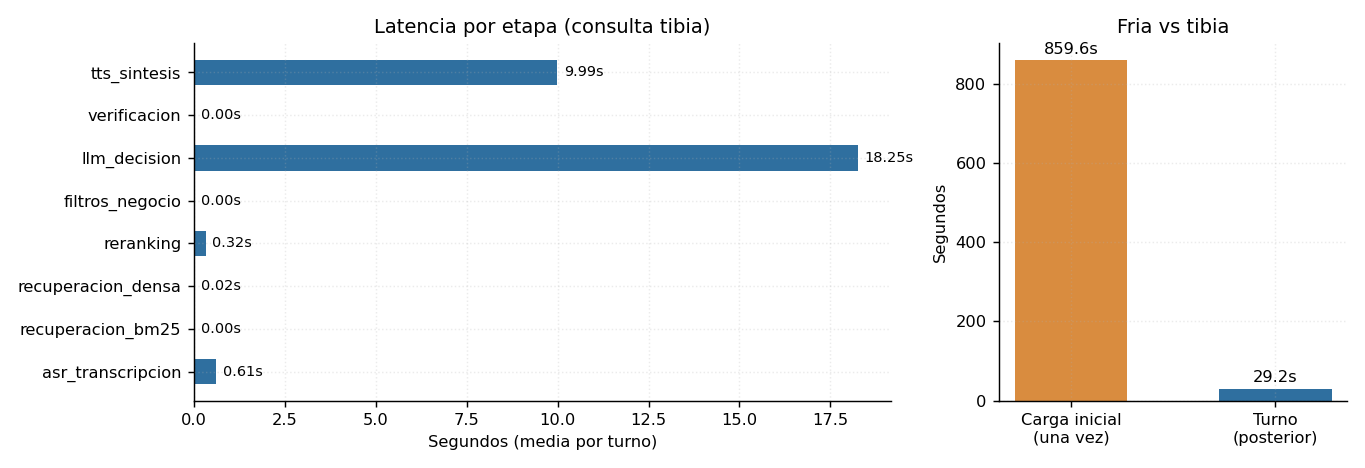

In [54]:
#@title 12.2 · Latencia por etapa
lat = INFORME_VOZ.latencia
print(f"CARGA INICIAL (una vez por sesión): {lat['total_carga_s']:.1f} s")
for k, v in lat["carga_modelos_s"].items():
    print(f"  {k:22s} {v:7.1f} s")

print(f"\nTURNO POSTERIOR (fin de grabación → audio listo): "
      f"{lat['total_tibio_medio_s']:.2f} s de media\n")
display(pd.DataFrame(lat["etapas"]).T)

from voiceshop.report import plot_latency
f = plot_latency(lat, cfg=CFG)
if f:
    display(Image(str(f)))

---
## 13. Informe, figuras y análisis

`results/RESULTADOS.md` se compone **solo** a partir de los JSON/CSV generados:
ningún número del informe está escrito a mano.

Edite `docs/analisis.json` con los cinco aciertos y los cinco fallos que
observe en **su** ejecución (las celdas 6.5, 10.3 y 11.3 le dan la evidencia) y
vuelva a ejecutar la celda 13.2.

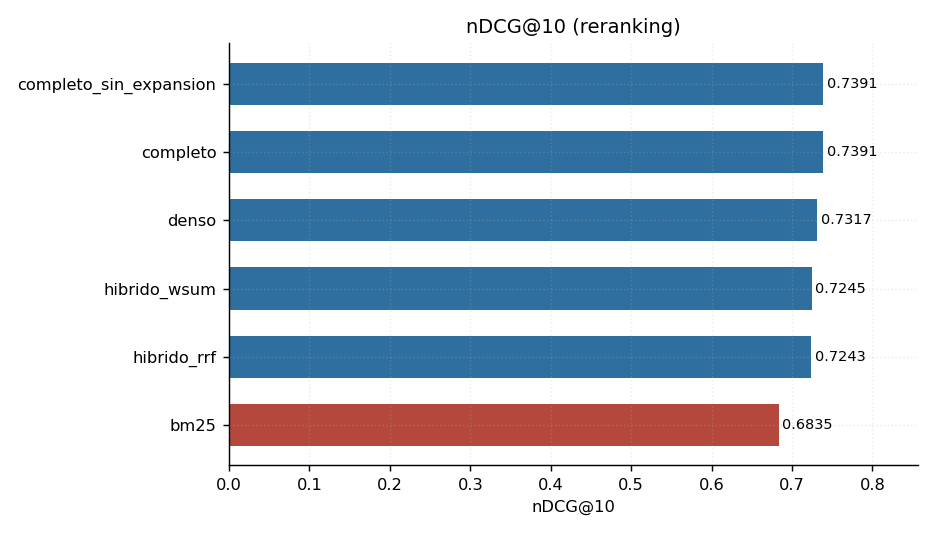

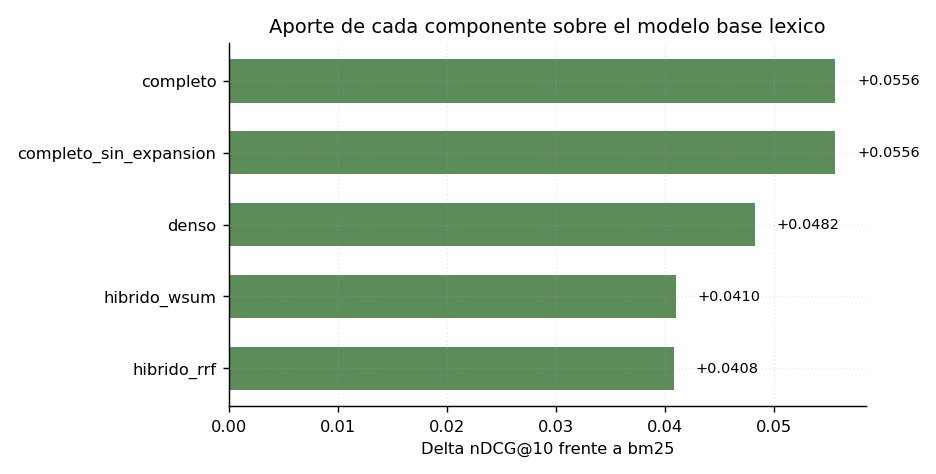

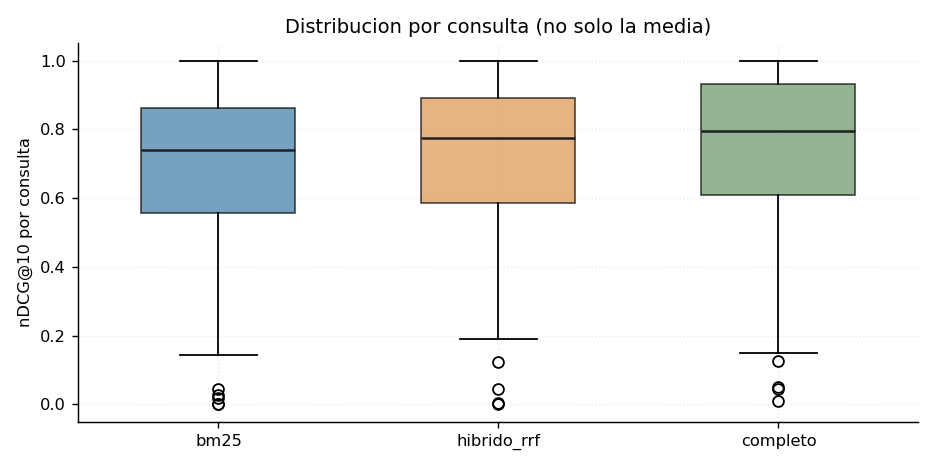

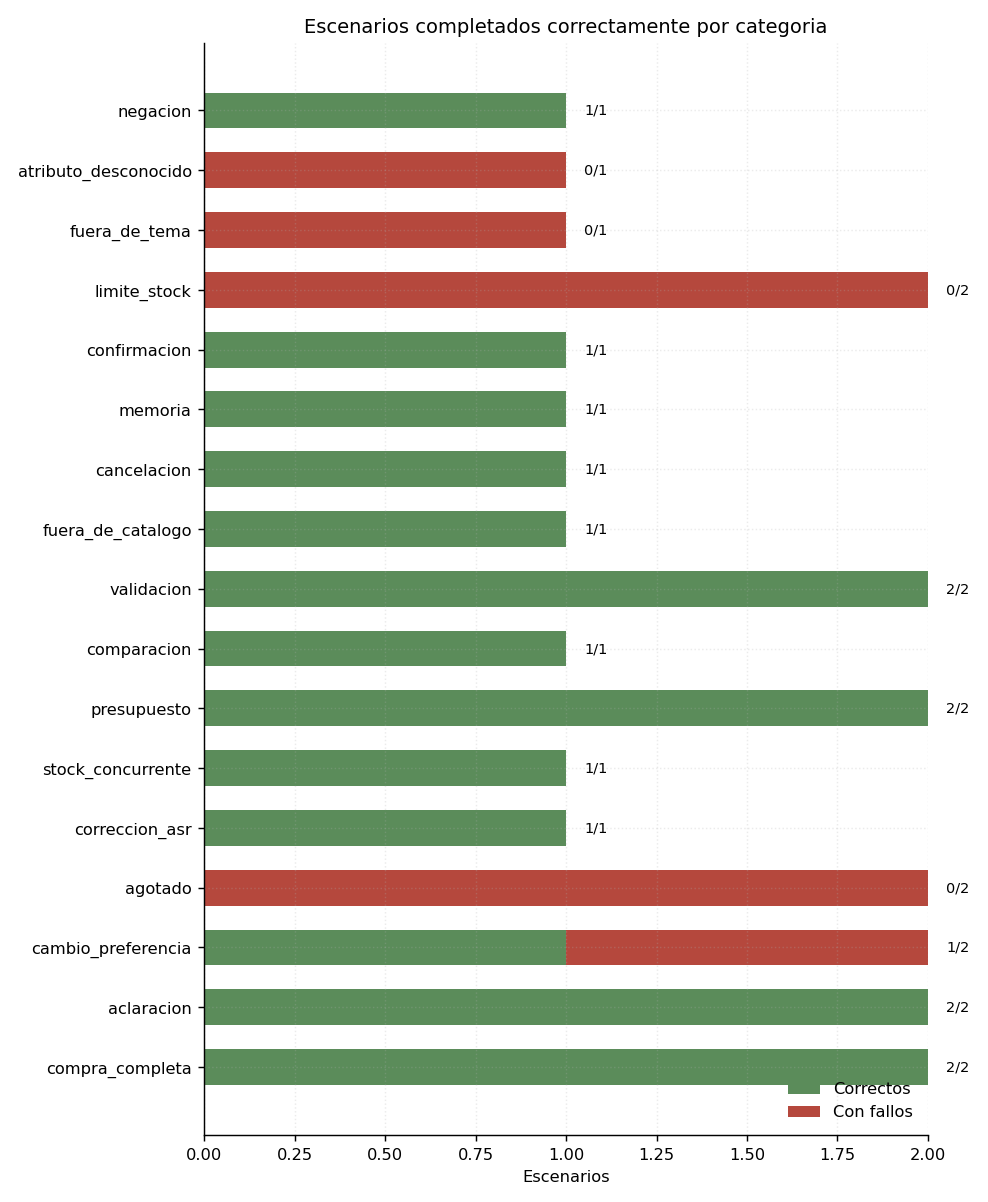

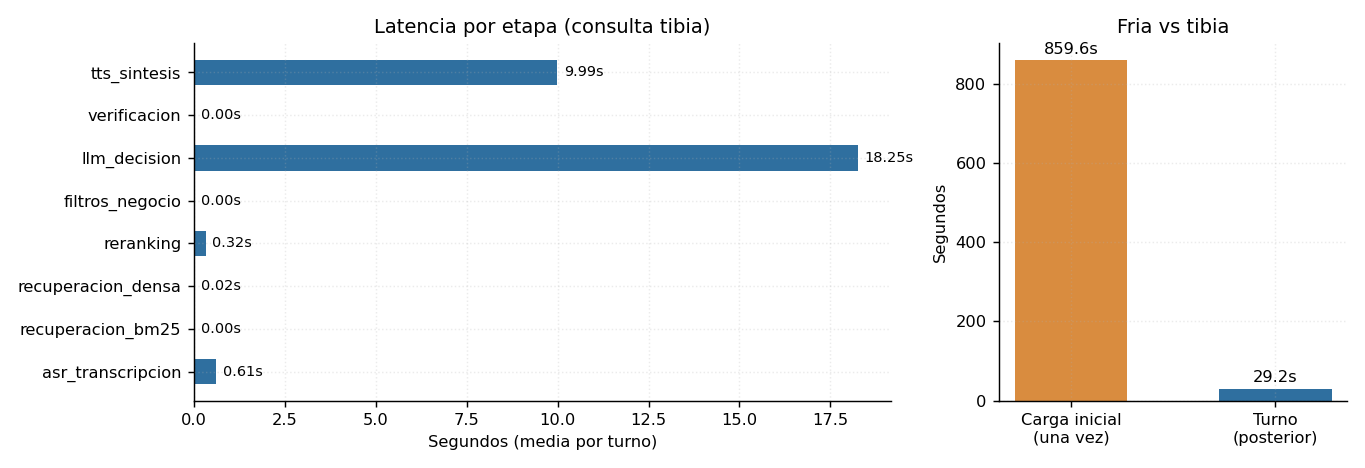

['/content/Laboratorio4/results/figures/ir_ndcg10_reranking.png', '/content/Laboratorio4/results/figures/ir_ablacion_delta.png', '/content/Laboratorio4/results/figures/ndcg_distribucion.png', '/content/Laboratorio4/results/figures/escenarios.png', '/content/Laboratorio4/results/figures/latencia.png']


In [55]:
#@title 13.1 · Todas las figuras
from voiceshop.report import make_all_figures
figs = make_all_figures(ir_result=IR_RERANK, resumen_escenarios=RESUMEN,
                        latencia=INFORME_VOZ.latencia, cfg=CFG)
for f in figs:
    display(Image(f))
print(figs)

In [56]:
#@title 13.2 · Generar results/RESULTADOS.md
from voiceshop.report import build_markdown_report
from voiceshop.utils import read_json, write_json

write_json(CFG.paths.results / "configuracion.json", CFG.to_dict())

ruta_analisis = CFG.paths.root / "docs" / "analisis.json"
extra = read_json(ruta_analisis) if ruta_analisis.exists() else {}
INFORME = build_markdown_report(cfg=CFG, extra=extra)

from IPython.display import Markdown
display(Markdown(INFORME.read_text(encoding="utf-8")[:6000]))
print(f"\n... informe completo en {INFORME}")

# Lo caro de recomputar, a Drive (no hace nada si se omitió la 2.3).
try:
    respaldar(verboso=False)
    print("  respaldado en Drive")
except NameError:
    pass

02:58:46 | INFO    | voiceshop          | Informe escrito en /content/Laboratorio4/results/RESULTADOS.md


# Laboratorio 4 - Asistente de compras por voz

Resultados generados automaticamente a partir de los artefactos de `results/`. Ningun numero de este documento esta escrito a mano.

## 1. Configuracion de la ejecucion

- Perfil de hardware: `colab_t4`
- LLM: `Qwen/Qwen2.5-3B-Instruct` (4-bit: True)
- Embeddings: `intfloat/multilingual-e5-base`
- Reranker: `BAAI/bge-reranker-base`
- ASR: `large-v3` (int8_float16)
- TTS: `tts_models/multilingual/multi-dataset/xtts_v2`
- Semilla: `20251111`

## 2. Datos

- Catalogo: **12336** productos (9836 anotados + 2500 distractores)
- Consultas: **220** de test y 150 de desarrollo
- Juicios de relevancia: 10119 (profundidad media 27.3)
- Distribucion ESCI: `{'E': 4066, 'S': 3499, 'I': 1836, 'C': 718}`

> Las etiquetas ESCI viven solo en `juicios.parquet` y no entran en el indice ni en el contexto del agente.

## 3. Recuperacion: modelo base y ablaciones

### 3.0 Preprocesado lexico de la linea base

BM25 (`bm25.py`, k1 = 1.2, b = 0.75) indexa el texto que devuelve `text_utils.analyze`, implementado sin NLTK ni spaCy para que no dependa de descargas en Colab. El mismo analizador se aplica al documento y a la consulta:

1. Minusculas y **supresion de tildes** por descomposicion NFKD, de modo que *camara* y *camara* con tilde caen en el mismo termino. Es lo que hace que una consulta dictada por voz, donde el ASR acentua de forma inconsistente, siga encontrando el producto.
2. La puntuacion pasa a espacio y los espacios se colapsan.
3. **Stopwords del espanol** (`STOPWORDS_ES`), ampliadas con los verbos de intencion propios del habla: *quiero*, *necesito*, *busco*, *muestrame*, *por favor*. En consultas dictadas son ruido puro.

   Esa lista incluye `sin` y `no`, y conviene declararlo porque tiene consecuencias: `analyze("radiador sin aceite")` devuelve `["radi", "aceite"]`. **La linea base lexica no ve la negacion: la borra.** Para BM25, *radiador sin aceite* y *radiador con aceite* son la misma consulta, y el producto que el usuario rechaza explicitamente puntua igual que el que quiere. No es un descuido del ajuste, es una limitacion estructural del modelo de bolsa de palabras, y es la razon de que la negacion se resuelva en el vecindario denso y se mida aparte.
4. Se descartan los tokens de un solo caracter salvo una lista blanca de medidas y formatos (*tv*, *4k*, *gb*, *ssd*, *xl*, *s*, *m*, *l*), que en un catalogo si discriminan.
5. **Stemmer ligero por sufijos** del espanol, no Snowball: recorta solo palabras de mas de 4 caracteres y nunca deja una raiz de menos de 3. Unifica la variacion dominante del catalogo, que es numero y genero: *funda* y *fundas* colapsan ambas en *fund*, igual que *adaptador* y *adaptadores*.

El modelo denso no comparte este preprocesado: recibe el texto tal cual, porque el tokenizador de E5 ya normaliza a su manera. La comparacion entre ambos es, por tanto, entre dos sistemas completos, no entre dos puntuaciones sobre el mismo analisis.

### Protocolo A - re-ranking de candidatos anotados

| sistema | configuracion | ndcg@10 | recall@10 | mrr | ms_por_consulta |
| --- | --- | --- | --- | --- | --- |
| completo | bm25+dense+rerank[rrf] | 0.7391 | 0.619 | 0.8424 | 151.2 |
| completo_sin_expansion | bm25+dense+rerank-noexp[rrf] | 0.7391 | 0.619 | 0.8424 | 152.9 |
| denso | dense | 0.7317 | 0.603 | 0.8327 | 22.2 |
| hibrido_wsum | bm25+dense[wsum] | 0.7245 | 0.5953 | 0.8379 | 36.4 |
| hibrido_rrf | bm25+dense[rrf] | 0.7243 | 0.5958 | 0.8419 | 24.5 |
| bm25 | bm25 | 0.6835 | 0.5709 | 0.7788 | 2.7 |

**Significancia (permutacion pareada, 10 000 iteraciones):**

| comparacion | diferencia | p | significativo |
| --- | --- | --- | --- |
| denso_vs_bm25 | 0.04825 | 0.0002 | True |
| hibrido_rrf_vs_bm25 | 0.04081 | 0.0 | True |
| hibrido_wsum_vs_bm25 | 0.04104 | 0.0 | True |
| completo_vs_bm25 | 0.05564 | 0.0 | True |
| completo_sin_expansion_vs_bm25 | 0.05564 | 0.0 | True |
| ablacion_reranker | 0.01483 | 0.1653 | False |
| ablacion_expansion | 0.0 | 1.0 | False |


### Protocolo B - recuperacion sobre catalogo completo

| sistema | configuracion | ndcg@10 | recall@10 | mrr | ms_por_consulta |
| --- | --- | --- | --- | --- | --- |
| completo_sin_expansion | bm25+dense+rerank-noexp[rrf] | 0.6225 | 0.5016 | 0.8027 | 256.8 |
| completo | bm25+dense+rerank[rrf] | 0.62 | 0.5014 | 0.7982 | 260.4 |
| hibrido_wsum | bm25+dense[wsum] | 0.598 | 0.4861 | 0.7657 | 25.3 |
| hibrido_rrf | bm25+dense[rrf] | 0.5944 | 0.4852 | 0.77 | 16.7 |
| denso | dense | 0.5638 | 0.454 | 0.7395 | 14.2 |
| bm25 | bm25 | 0.5492 | 0.4572 | 0.7025 | 0.8 |

**Significancia (permutacion pareada, 10 000 iteraciones):**

| comparacion | diferencia | p | significativo |
| --- | --- | --- | --- |
| denso_vs_bm25 | 0.01463 | 0.3951 | False |
| hibrido_rrf_vs_bm25 | 0.04517 | 0.0001 | True |
| hibrido_wsum_vs_bm25 | 0.04879 | 0.0001 | True |
| completo_vs_bm25 | 0.07085 | 0.0 | True |
| completo_sin_expansion_vs_bm25 | 0.07334 | 0.0 | True |
| ablacion_reranker | 0.02568 | 0.0219 | True |
| ablacion_expansion | -0.00249 | 0.1859 | False |


![nDCG por sistema](figures/ir_ndcg10_reranking.png)

![Aporte de cada componente](figures/ir_ablacion_delta.png)

![Distribucion por consulta](figures/ndcg_distribucion.png)

## 4. Escenarios operativos

- Escenarios evaluados: **24**
- Completados correctamente: **17** (70.8 %)
- Aserciones superadas: 68/79 (86.1 %)
- Incumplimientos de restricciones: **0**
- Escenarios con fallos: `E03, E04, E14, E18, E19, E21, E22`

![Escenarios](figures/escenarios.png)

## 5. Voz: ASR, TTS y latencia

### 5.1 Transcripcion

- Turnos de voz evaluados: 20
- WER medio: **0.0193** (mediana 0.0)
- Turnos con error en **cantidades**: 0 (tasa 0.0)
- Turnos con error en **importes**: 0 (tasa 0.0)
- Turnos con error en **terminos de producto**: 3
- Desglose sobre 137 palabras de referencia: **3 sustituciones** (tasa 0.0219), **0 omisiones** (tasa 0.0), **0 inserciones** (tasa 0.0).
  El WER global suma los tres, pero no cuestan igual: una sustitucion puede 


... informe completo en /content/Laboratorio4/results/RESULTADOS.md
  respaldado en Drive


In [57]:
#@title 13.3 · Empaquetar la evidencia para la entrega
import shutil
paquete = CFG.paths.root / "entrega_resultados"
if paquete.exists():
    shutil.rmtree(paquete)
paquete.mkdir(parents=True)
shutil.copytree(CFG.paths.results, paquete / "results")
shutil.copytree(CFG.paths.processed, paquete / "data_processed",
                ignore=shutil.ignore_patterns("*.npz"))

# El enunciado exige el codigo y los audios, y sin `src/voiceshop` el notebook
# no se puede ejecutar: la entrega anterior no los llevaba.
raiz_src = CFG.paths.root / "src" / "voiceshop"
if raiz_src.exists():
    shutil.copytree(raiz_src, paquete / "src" / "voiceshop",
                    ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
    print(f"  src/voiceshop: {len(list((paquete / 'src' / 'voiceshop').glob('*.py')))} modulos")
for sub in ("tests", "docs"):
    if (CFG.paths.root / sub).exists():
        shutil.copytree(CFG.paths.root / sub, paquete / sub,
                        ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
for carpeta, destino in (("audio_usuario", "audio_usuario"),
                         ("audio_ref", "audio_ref"),
                         ("audio_out", "audio_out")):
    origen = CFG.paths.assets / carpeta
    if origen.exists() and any(origen.iterdir()):
        shutil.copytree(origen, paquete / "assets" / destino)
        print(f"  assets/{destino}: {len(list((paquete / 'assets' / destino).glob('*.wav')))} wav")
    else:
        print(f"  AVISO: assets/{carpeta} vacia o ausente")
nb = CFG.paths.root / "Laboratorio4_Asistente_Compras_Voz.ipynb"
if nb.exists():
    shutil.copy2(nb, paquete / nb.name)
zip_path = shutil.make_archive(str(CFG.paths.root / "entrega_resultados"),
                               "zip", paquete)
print(f"Paquete: {zip_path}")
if "google.colab" in sys.modules:
    from google.colab import files
    files.download(zip_path)

  src/voiceshop: 25 modulos
  assets/audio_usuario: 20 wav
  assets/audio_ref: 2 wav
  AVISO: assets/audio_out vacia o ausente
Paquete: /content/Laboratorio4/entrega_resultados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 14. Gestión de memoria

El `ResourceManager` descarga de VRAM lo que no participa en la etapa actual.
Esta celda muestra el balance de la sesión y libera todo.

In [58]:
#@title 14.1 · Balance de recursos y liberación
print("Antes de liberar:", gpu_memory_report())
print("\nEstado de componentes:")
for k, v in AGENTE.resources.report()["componentes"].items():
    print(f"  {k:10s} cargado={v}")
print(f"\nTransiciones de carga/descarga: "
      f"{AGENTE.resources.report()['transiciones']}")
print(f"Uso del LLM: {LLM.usage.to_dict()}")

AGENTE.resources.unload_all()
RETRIEVER.unload_models()
print("\nDespués de liberar:", gpu_memory_report())

Antes de liberar: {'total_gb': 14.56, 'libre_gb': 1.88, 'reservada_gb': 10.99, 'asignada_gb': 6.77}

Estado de componentes:
  llm        cargado=True
  asr        cargado=True
  tts        cargado=True
  reranker   cargado=True
  encoder    cargado=True

Transiciones de carga/descarga: 5
Uso del LLM: {'llamadas': 520, 'tokens_prompt': 1078201, 'tokens_generados': 27160, 'segundos': 3227.454}

Después de liberar: {'total_gb': 14.56, 'libre_gb': 12.24, 'reservada_gb': 2.17, 'asignada_gb': 2.06}


---

## Resumen de cumplimiento del enunciado

| Requisito | Dónde |
|---|---|
| ASR integrado con la conversación en español | §7.2, §9, `src/voiceshop/asr.py` |
| RAG sobre el catálogo, atributos no verificables = desconocidos | §5, §6, `retriever.py`, `tools.py::_t_detalle` |
| Agente que elige operaciones y registra pedidos | §8, `agent.py`, `tools.py` |
| Estado de la conversación y aclaraciones | §8.3, `state.py`, `policy.py` |
| Validación en código de cantidad, presupuesto y stock | `store.py`, `tools.py::validate_args` |
| Revalidación al confirmar, sin parciales ni duplicados | §4.2, §11, `store.place_order` |
| Voz propia con grabación de referencia, textos distintos | §7.1, §7.3, `tts.py` |
| Comparación con modelo base léxico | §6.1–6.3 (`bm25`) |
| Ablación de un componente | §6.3 (cross-encoder y expansión) |
| ≥ 20 escenarios con estado inicial reproducible | §10, `scenarios.py`, `runner.py` |
| 6 escenarios por voz, ≥ 3 multi-turno | §11, `voice_scenarios()` |
| Réplica con transcripción correcta | §11.2, `run_voice_and_text` |
| nDCG@10 con ganancias 1 / 0,1 / 0,01 / 0 | §6, `ir_metrics.py` |
| % escenarios correctos, incumplimientos, errores de ASR | §10.2, §12.1 |
| Inteligibilidad y semejanza de voz | §7.4, §12.1 |
| Latencia por etapa, fría vs tibia | §12.2 |
| Sin ajustar con las consultas de evaluación | `split='test'` solo se mide; el ajuste usa `dev` |
| Todo el cómputo dentro de Colab | §1, sin APIs externas |